### LSE Data Analytics Online Career Accelerator 

# DA301:  Advanced Analytics for Organisational Impact

## Assignment template

### Scenario
You are a data analyst working for Turtle Games, a game manufacturer and retailer. They manufacture and sell their own products, along with sourcing and selling products manufactured by other companies. Their product range includes books, board games, video games and toys. They have a global customer base and have a business objective of improving overall sales performance by utilising customer trends. In particular, Turtle Games wants to understand: 
- how customers accumulate loyalty points (Week 1)
- exploring the structure using decision trees (Week 2)
- exploring clusters in customer behaviour (Week 3)
- can social data (e.g. customer reviews) be used in marketing campaigns (Week 4)
- loading, transforming and visualising data in R (Week 5)
- statistical analysis and modelling in R (Week 6)

# Week 1 assignment: Linear regression using Python
The marketing department of Turtle Games prefers Python for data analysis. As you are fluent in Python, they asked you to assist with data analysis of social media data. The marketing department wants to better understand how users accumulate loyalty points. Therefore, you need to investigate the possible relationships between the loyalty points, age, remuneration, and spending scores. Note that you will use this data set in future modules as well and it is, therefore, strongly encouraged to first clean the data as per provided guidelines and then save a copy of the clean data for future use.

## Instructions
1. Load and explore the data.
    1. Create a new DataFrame (e.g. reviews).
    2. Sense-check the DataFrame.
    3. Determine if there are any missing values in the DataFrame.
    4. Create a summary of the descriptive statistics.
2. Remove redundant columns (`language` and `platform`).
3. Change column headings to names that are easier to reference (e.g. `renumeration` and `spending_score`).
4. Save a copy of the clean DataFrame as a CSV file. Import the file to sense-check.
5. Use linear regression and goodness of fit metrics to evaluate possible linear relationships between loyalty points and age/renumeration/spending scores to determine whether these can be used to predict the loyalty points.
    1. Specify the independent and dependent variables.
    2. Create the OLS model.
    3. Extract the estimated parameters, standard errors, and predicted values.
    4. Generate the regression table based on the X coefficient and constant values.
    5. Plot the linear regression and add a regression line.
6. Include your insights and observations.

## 1. Load and explore the data

In [124]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm 
from statsmodels.formula.api import ols

### 1.1 Loading the data

In [125]:
# Load the CSV file(s) as reviews.

turtle_df = pd.read_csv('turtle_reviews.csv')

# View the DataFrame.

turtle_df.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
0,Male,18,12.30,39,210,graduate,EN,Web,453,"When it comes to a DM's screen, the space on the screen itself is at an absolute premium. The fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless. The only reason that I gave it 2 stars and not 1 was that, technically speaking, it can at least still stand up to block your notes and dice rolls. Other than that, it drops the ball completely.",The fact that 50% of this space is wasted on art (and not terribly informative or needed art ...
1,Male,23,12.30,81,524,graduate,EN,Web,466,"An Open Letter to GaleForce9*:\n\nYour unpainted miniatures are very not bad. Your spell cards are great. Your board games are ""meh"". Your DM screens, however, are freaking terrible. I'm still waiting for a single screen that isn't polluted with pointless artwork where useful, reference-able tables should be. Once again, you've created a single use screen that is only useful when running the ""Storm King's Thunder"" adventure. Even despite the fact that it's geared to that adventure path, it's usefulness negligible, at best. I massive swath of the inner panel is wasted on artwork and a bloated overland map, which could have been easily reduced to a single panel in size. And the few table you have are nigh-useless themselves.\n\nIn short, stop making crap DM screens.",Another worthless Dungeon Master's screen from GaleForce9
2,Female,22,13.12,6,40,graduate,EN,Web,254,"Nice art, nice printing. Why two panels are filled with a general Forgotten Realms map is beyond me. Most of one of them is all blue ocean. Such a waste.\n\nI don't understand why they can't make these DM Screens more useful for these ""kinds of adventures"" rather than solely the specific adventure. You're supposed to be able to transpose this adventure to other lands outside the Forgotten Realms. So even just a list of new monsters or NPCs would at least be useful than the map. Even more would just be stuff related to running the game but broad-use stuff related to giants.\n\nSame thing with Curse of Strahd. Why not make it useful for raven loft, undead or horror campaigns in general... instead a huge amount of screen space is solely mapping out Castle Ravenloft, which is only useful during a small fraction of the time even for the Curse of Strahd adventure, let alone various other Ravenloft adventuring.\n\nThey really kill the extended use of these screens by not thinking about their potential use, both for the adventure in question, as well as use in a broader sense.\n\nThe Rage of Demons screen is far more useful for broad under dark adventuring - covering a lot of rules for the various conditions you may suffer... and the map is only one panel.\n\nThis Storm Giants one is decent for a few tables it includes - but really misses the mark. Maybe they should ask a few DMs what they would use?","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,EN,Web,263,Amazing buy! Bought it as a gift for our new dm and it's perfect!,Five Stars
4,Female,33,13.94,40,366,graduate,EN,Web,291,"As my review of GF9's previous screens these were completely unnecessary and nearly useless. Skip them, this is the definition of a waste of money.",Money trap


In [126]:
# Any missing values?
turtle_df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   object 
 1   age                     2000 non-null   int64  
 2   remuneration (k£)       2000 non-null   float64
 3   spending_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   object 
 6   language                2000 non-null   object 
 7   platform                2000 non-null   object 
 8   product                 2000 non-null   int64  
 9   review                  2000 non-null   object 
 10  summary                 2000 non-null   object 
dtypes: float64(1), int64(4), object(6)
memory usage: 172.0+ KB


In [127]:
# Statistics of the dataset

turtle_df.describe(include='all')

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
count,2000,2000.000000,2000.000000,2000.000000,2000.000000,2000,2000,2000,2000.000000,2000,2000
unique,2,NaN,NaN,NaN,NaN,5,1,1,NaN,1980,1432
top,Female,NaN,NaN,NaN,NaN,graduate,EN,Web,NaN,love it,Five Stars
freq,1120,NaN,NaN,NaN,NaN,900,2000,2000,NaN,5,378
mean,NaN,39.495000,48.079060,50.000000,1578.032000,NaN,NaN,NaN,4320.521500,NaN,NaN
std,NaN,13.573212,23.123984,26.094702,1283.239705,NaN,NaN,NaN,3148.938839,NaN,NaN
min,NaN,17.000000,12.300000,1.000000,25.000000,NaN,NaN,NaN,107.000000,NaN,NaN
25%,NaN,29.000000,30.340000,32.000000,772.000000,NaN,NaN,NaN,1589.250000,NaN,NaN
50%,NaN,38.000000,47.150000,50.000000,1276.000000,NaN,NaN,NaN,3624.000000,NaN,NaN
75%,NaN,49.000000,63.960000,73.000000,1751.250000,NaN,NaN,NaN,6654.000000,NaN,NaN


### 1.2 Checking Predictor Distribution 


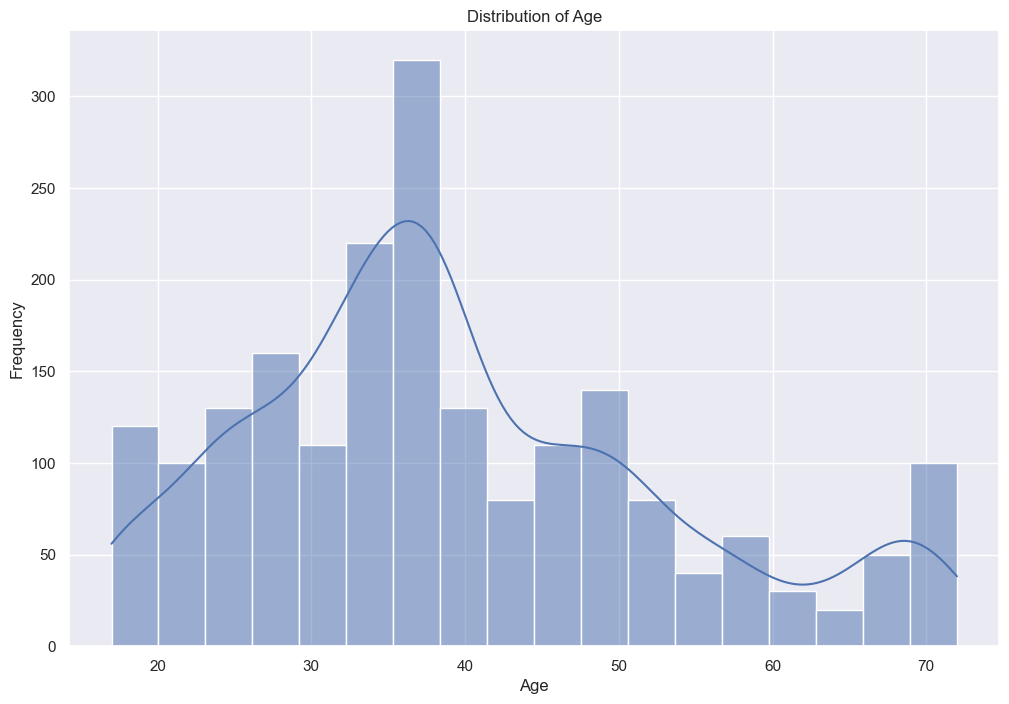

In [128]:
# Explore the data.

# Distribution of age column

sns.histplot(turtle_df['age'], kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

No apparent outliers seen. Although we can see that we have more skew towards the right indicating that we have more older aged people than younger ones

This may cause heteroskedasticity----> need to check

Most people are in the 36 - 39 range followed by 39 -42

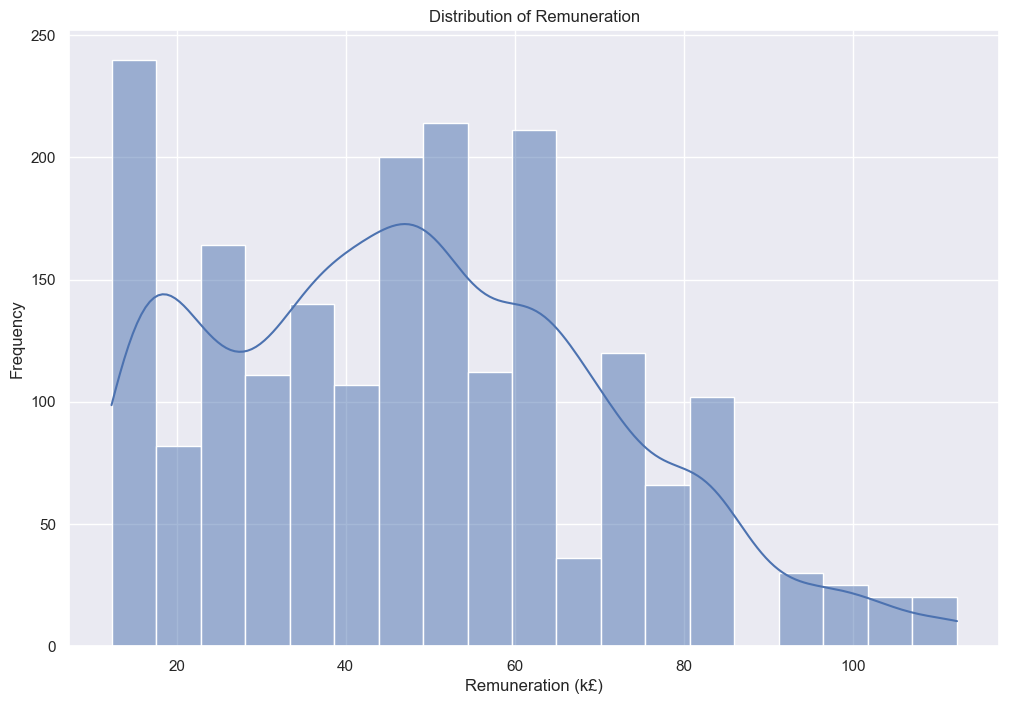

In [129]:
# Distribution of Remuneration

sns.histplot(turtle_df['remuneration (k£)'], kde=True)
plt.title('Distribution of Remuneration')
plt.xlabel('Remuneration (k£)')
plt.ylabel('Frequency')
plt.show()

Evidence for apparent outliers seen. Right skew visible. Also may be two categories of remuneration available - 0-25 and 40-55

This may cause heteroskedasticity----> need to check

Most people are in the 40 -60 range 

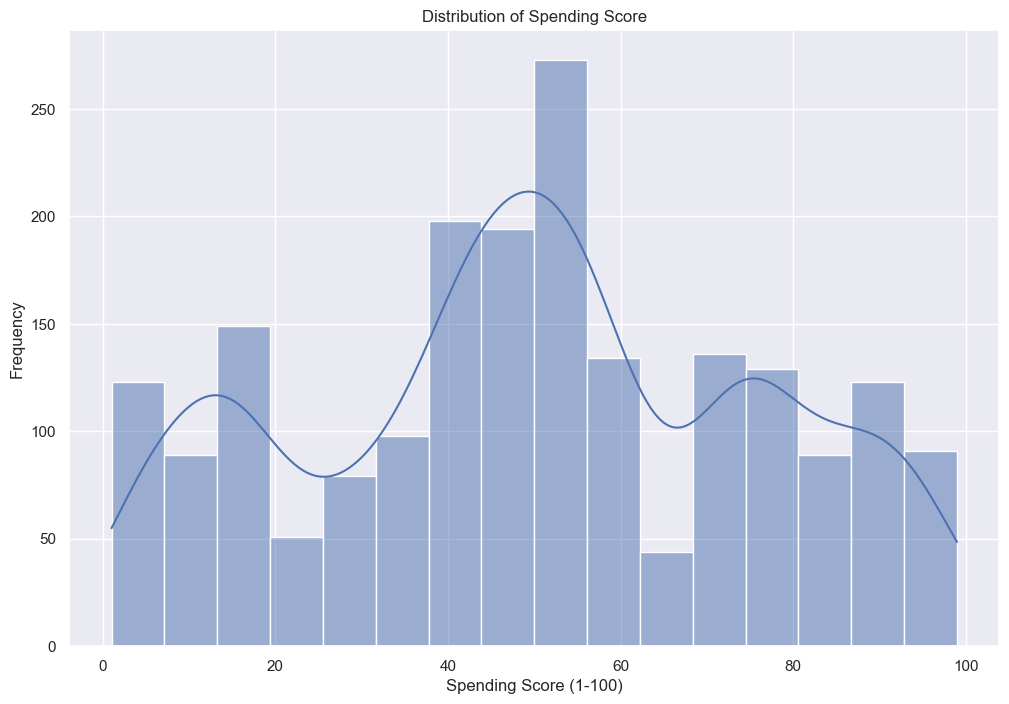

In [130]:
# Distribution of spending_score (1-100)

sns.histplot(turtle_df['spending_score (1-100)'], kde=True)
plt.title('Distribution of Spending Score')
plt.xlabel('Spending Score (1-100)')
plt.ylabel('Frequency')
plt.show()

A bimodal graph indicating that we have different categories of spending present in the population

e.g categ 1 with score 0-20 (smaller group) and categ 2 with 40-60 ( larger group) and categ 3 with 70 -80 ( smaller group)

no indication of skewness here--> less chance for heteroskedasticity due to this variable

### 1.3 Checking target distribution

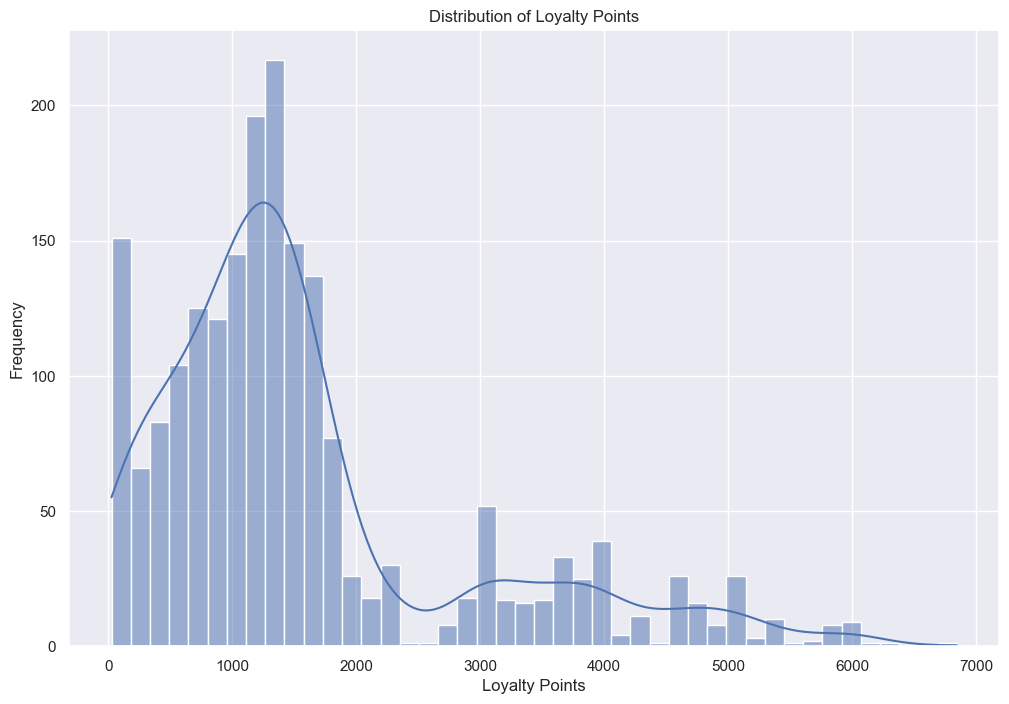

In [131]:
# Distribution of the loyalty  points 

sns.histplot(turtle_df['loyalty_points'], kde=True)
plt.title('Distribution of Loyalty Points')
plt.xlabel('Loyalty Points')
plt.ylabel('Frequency')
plt.show()

### 1.4 Checking correlations between variables

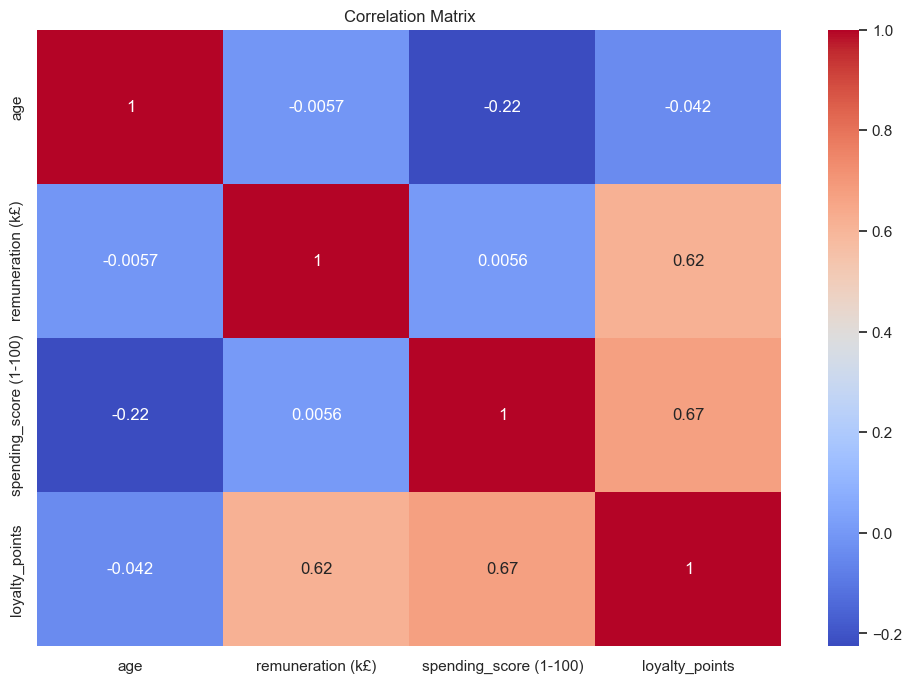

In [ ]:
# Correlation matrix

columns = ['age', 'remuneration (k£)', 'spending_score (1-100)', 'loyalty_points']
corr_matrix = turtle_df[columns].corr() 
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

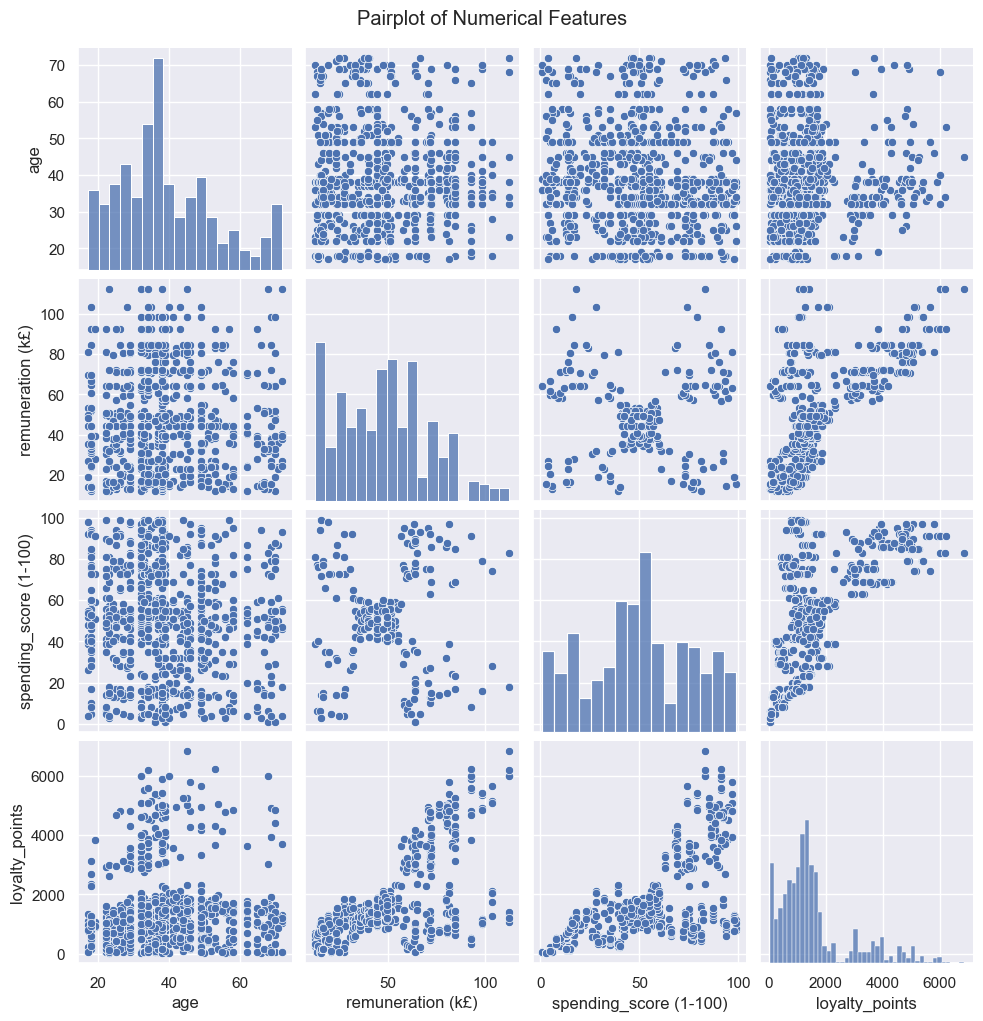

In [ ]:
# Pairplot of numerical features  

g = sns.pairplot(turtle_df[columns])
g.fig.suptitle('Pairplot of Numerical Features', y=1.02)
plt.show()

Negligible correlations between each predictor variables (need to check at the residual level to be certain)

good enough correlations between target and each predictor variables except for age ( is age a good predictor)

In [56]:
# Basic descriptive statistics.

turtle_df.describe(include='all')

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
count,2000,2000.000000,2000.000000,2000.000000,2000.000000,2000,2000,2000,2000.000000,2000,2000
unique,2,NaN,NaN,NaN,NaN,5,1,1,NaN,1980,1432
top,Female,NaN,NaN,NaN,NaN,graduate,EN,Web,NaN,love it,Five Stars
freq,1120,NaN,NaN,NaN,NaN,900,2000,2000,NaN,5,378
mean,NaN,39.495000,48.079060,50.000000,1578.032000,NaN,NaN,NaN,4320.521500,NaN,NaN
std,NaN,13.573212,23.123984,26.094702,1283.239705,NaN,NaN,NaN,3148.938839,NaN,NaN
min,NaN,17.000000,12.300000,1.000000,25.000000,NaN,NaN,NaN,107.000000,NaN,NaN
25%,NaN,29.000000,30.340000,32.000000,772.000000,NaN,NaN,NaN,1589.250000,NaN,NaN
50%,NaN,38.000000,47.150000,50.000000,1276.000000,NaN,NaN,NaN,3624.000000,NaN,NaN
75%,NaN,49.000000,63.960000,73.000000,1751.250000,NaN,NaN,NaN,6654.000000,NaN,NaN


## 2. Drop columns

In [57]:
# Drop unnecessary columns.

turtle_df = turtle_df.drop(columns=['language', 'platform'])

# View column names.

print(turtle_df.columns)


Index(['gender', 'age', 'remuneration (k£)', 'spending_score (1-100)',
       'loyalty_points', 'education', 'product', 'review', 'summary'],
      dtype='object')


## 3. Rename columns

In [58]:
# Rename the column headers.

turtle_df = turtle_df.rename(columns={
    'remuneration (k£)': 'remuneration',
    'spending_score (1-100)': 'spending_score'})


# View column names.

print(turtle_df.columns)

Index(['gender', 'age', 'remuneration', 'spending_score', 'loyalty_points',
       'education', 'product', 'review', 'summary'],
      dtype='object')


## 4. Save the DataFrame as a CSV file

In [22]:
# Create a CSV file as output.

turtle_df.to_csv('turtle_reviews_cleaned.csv', index=False)

In [59]:
# Import new CSV file with Pandas.

turtle_df = pd.read_csv('turtle_reviews_cleaned.csv')

# View DataFrame.

turtle_df.head()    

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


## 5. Linear regression

### 5.1 spending vs loyalty Model

In [60]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Define independent variable.
y_spend = turtle_df['loyalty_points']

# Define dependent variable.
X_spend = turtle_df[ 'spending_score']

# Create model and print summary of metrics.

formula_spend = 'loyalty_points ~ spending_score'
model_spend = ols(formula_spend, data=turtle_df).fit()
print(model_spend.summary())

                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.452
Model:                            OLS   Adj. R-squared:                  0.452
Method:                 Least Squares   F-statistic:                     1648.
Date:                Wed, 31 Dec 2025   Prob (F-statistic):          2.92e-263
Time:                        01:01:09   Log-Likelihood:                -16550.
No. Observations:                2000   AIC:                         3.310e+04
Df Residuals:                    1998   BIC:                         3.312e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        -75.0527     45.931     -1.

In [61]:
# Extract the estimated parameters.
params_spend = model_spend.params
print(params_spend)

# Extract the standard errors.
std_errors_spend = model_spend.bse
print(std_errors_spend)

# Extract the predicted values.
predictions_spend = model_spend.predict(X_spend)
print(predictions_spend)

Intercept        -75.052663
spending_score    33.061693
dtype: float64
Intercept         45.930554
spending_score     0.814419
dtype: float64
0       1214.353374
1       2602.944491
2        123.317497
3       2470.697718
4       1247.415067
           ...     
1995    2206.204172
1996     189.440883
1997    2933.561424
1998     453.934429
1999     189.440883
Length: 2000, dtype: float64


In [62]:
# Set the X coefficient and the constant to generate the regression table.
const_spend  = params_spend.iloc[0]

x_coeff_spend = params_spend.iloc[1]

errors_spend = std_errors_spend.iloc[1]

reg_ouput_spend = {
    'Constant': const_spend,
    'X Coefficient': x_coeff_spend,
    'Error Terms': errors_spend
}

# View the output.
print(reg_ouput_spend) 
print(model_spend.summary())

{'Constant': -75.05266293364832, 'X Coefficient': 33.06169325867298, 'Error Terms': 0.8144185085135353}
                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.452
Model:                            OLS   Adj. R-squared:                  0.452
Method:                 Least Squares   F-statistic:                     1648.
Date:                Wed, 31 Dec 2025   Prob (F-statistic):          2.92e-263
Time:                        01:01:13   Log-Likelihood:                -16550.
No. Observations:                2000   AIC:                         3.310e+04
Df Residuals:                    1998   BIC:                         3.312e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [63]:
# want to see prediction errors and the generalizability of the model

# r2_score is used below; import it from sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import r2_score, mean_absolute_error

X_train_spend, X_test_spend, y_train_spend, y_test_spend = train_test_split(
    X_spend, y_spend, test_size=0.2, random_state=41)

### 5c Simple Regression Model - Spend vs Loyalty Points
# add constant for intercept term
X_train_spend = sm.add_constant(X_train_spend)

# Use statsmodels.api.OLS for array-like inputs (ols with formula expects a DataFrame and a formula string)
model_spend_train = sm.OLS(y_train_spend, X_train_spend).fit()

# Predict on the test set (remember to add constant)
X_test_spend_const = sm.add_constant(X_test_spend)
y_pred_spend = model_spend_train.predict(X_test_spend_const)

# Print the summary statistics
print("Training Set Regression Results:")
print(model_spend_train.summary())
print('------------------------------------------------------------')

# print the rsquared values and compare
print('Rsquared for train set:  ', model_spend_train.rsquared)
print('Rsquared for test set:  ', r2_score(y_test_spend, y_pred_spend))
print('------------------------------------------------------------')

# Calculate Mean Squared Error, Mean Absolute error and Root Mean Squared Error
from sklearn.metrics import mean_squared_error

print(f'Mean Squared Error on Test Set: {mean_squared_error(y_test_spend, y_pred_spend)}')
print(f'Mean Absolute Error on Test Set: {mean_absolute_error(y_test_spend, y_pred_spend)}')
print(f'Root Mean Squared Error on Test Set: {np.sqrt(mean_squared_error(y_test_spend, y_pred_spend))}')

Training Set Regression Results:
                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.451
Model:                            OLS   Adj. R-squared:                  0.451
Method:                 Least Squares   F-statistic:                     1312.
Date:                Wed, 31 Dec 2025   Prob (F-statistic):          2.85e-210
Time:                        01:01:16   Log-Likelihood:                -13218.
No. Observations:                1600   AIC:                         2.644e+04
Df Residuals:                    1598   BIC:                         2.645e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const      

### 5.1.1 Heteroskedasticity of spending vs loyalty model

In [64]:
# checking for the heteroskedasticity
import statsmodels.stats.api as sms
import statsmodels.api as sm
from statsmodels.formula.api import ols

# conducting the brauch Pagan Test

bp_test_spend = sms.het_breuschpagan(model_spend.resid, model_spend.model.exog)
labels = ['Lagrange multiplier statistic', 'p-value', 
          'f-value', 'f p-value']
print(dict(zip(labels, bp_test_spend)))

{'Lagrange multiplier statistic': 629.9823360215923, 'p-value': 5.042699614939363e-139, 'f-value': 918.7507142907754, 'f p-value': 2.3037887924479145e-166}


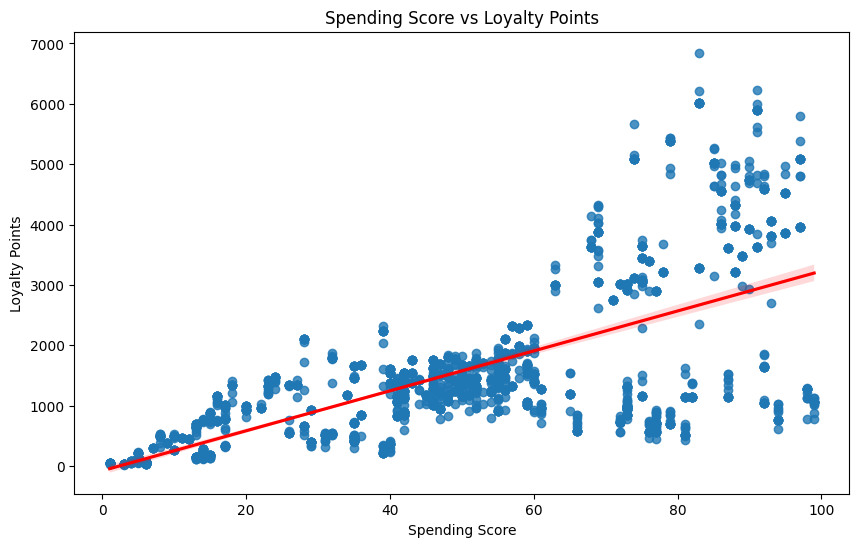

In [ ]:
# Plot the graph with a regression line.
plt.figure(figsize=(10, 6))
sns.regplot(x=X_spend, y=y_spend,line_kws={"color": "red"})
plt.title('Spending Score vs Loyalty Points')
plt.xlabel('Spending Score')
plt.ylabel('Loyalty Points')
plt.show()



### 5.1.2 Histogram plot of spending vs loyalty model residuals

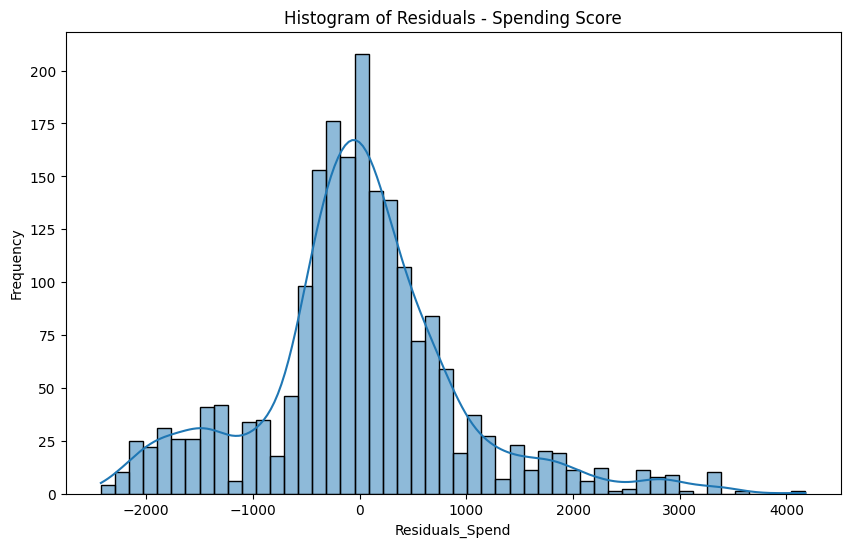

In [66]:
# Histogram plot of Spending Score residuals 

residuals = model_spend.resid
plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True)
plt.title('Histogram of Residuals - Spending Score')
plt.xlabel('Residuals_Spend')
plt.ylabel('Frequency')
plt.show()

### 5.2 renumeration vs loyalty model

In [67]:
# Define independent variable.
y_rem = turtle_df['loyalty_points']     

# Define dependent variable.
X_rem = turtle_df['remuneration']

# Create model and print summary of metrics.
model_rem = ols('loyalty_points ~ remuneration', data=turtle_df).fit()
print(model_rem.summary())

                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.380
Model:                            OLS   Adj. R-squared:                  0.379
Method:                 Least Squares   F-statistic:                     1222.
Date:                Wed, 31 Dec 2025   Prob (F-statistic):          2.43e-209
Time:                        01:01:45   Log-Likelihood:                -16674.
No. Observations:                2000   AIC:                         3.335e+04
Df Residuals:                    1998   BIC:                         3.336e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -65.6865     52.171     -1.259   

In [68]:
# Extract the estimated parameters.
params_rem = model_rem.params
print(params_rem)

# Extract the standard errors.
errors_rem = model_rem.bse
print(errors_rem)

# Extract the predicted values.
predictions_rem = model_rem.predict(X_rem)
print(predictions_rem)

Intercept      -65.686513
remuneration    34.187825
dtype: float64
Intercept       52.170717
remuneration     0.977925
dtype: float64
0        354.823741
1        354.823741
2        382.857758
3        382.857758
4        410.891774
           ...     
1995    2821.817228
1996    3102.157397
1997    3102.157397
1998    3298.395515
1999    3102.157397
Length: 2000, dtype: float64


In [69]:
# Set the the X coefficient and the constant to generate the regression table.

Reg_table = {
    'Constant': params_rem.iloc[0],
    'X Coefficient': params_rem.iloc[1],
    'Error Terms': errors_rem.iloc[1]
}

# View the output.

print(Reg_table)

print(model_rem.summary())

{'Constant': -65.68651279499436, 'X Coefficient': 34.18782548566869, 'Error Terms': 0.9779254568320916}
                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.380
Model:                            OLS   Adj. R-squared:                  0.379
Method:                 Least Squares   F-statistic:                     1222.
Date:                Wed, 31 Dec 2025   Prob (F-statistic):          2.43e-209
Time:                        01:01:48   Log-Likelihood:                -16674.
No. Observations:                2000   AIC:                         3.335e+04
Df Residuals:                    1998   BIC:                         3.336e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------

In [70]:
# want to see prediction errors and the generalizability of the model

# r2_score is used below; import it from sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import r2_score, mean_absolute_error

X_train_rem, X_test_rem, y_train_rem, y_test_rem = train_test_split(
    X_rem, y_rem, test_size=0.2, random_state=41)

### 5c Simple Regression Model - Spend vs Loyalty Points
# add constant for intercept term
X_train_rem = sm.add_constant(X_train_rem)

# Use statsmodels.api.OLS for array-like inputs (ols with formula expects a DataFrame and a formula string)
model_rem_train = sm.OLS(y_train_rem, X_train_rem).fit()

# Predict on the test set (remember to add constant)
X_test_rem_const = sm.add_constant(X_test_rem)
y_pred_rem = model_spend_train.predict(X_test_rem_const)

# Print the summary statistics
print("Training Set Regression Results:")
print(model_rem_train.summary())
print('------------------------------------------------------------')

# print the rsquared values and compare
print('Rsquared for train set:  ', model_rem_train.rsquared)
print('Rsquared for test set:  ', r2_score(y_test_rem, y_pred_rem))
print('------------------------------------------------------------')


# Calculate Mean Squared Error, Mean Absolute error and Root Mean Squared Error
from sklearn.metrics import mean_squared_error

print(f'Mean Squared Error on Test Set: {mean_squared_error(y_test_rem, y_pred_rem)}')
print(f'Mean Absolute Error on Test Set: {mean_absolute_error(y_test_rem, y_pred_rem)}')
print(f'Root Mean Squared Error on Test Set: {np.sqrt(mean_squared_error(y_test_rem, y_pred_rem))}')

Training Set Regression Results:
                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.379
Model:                            OLS   Adj. R-squared:                  0.378
Method:                 Least Squares   F-statistic:                     974.7
Date:                Wed, 31 Dec 2025   Prob (F-statistic):          1.88e-167
Time:                        01:01:51   Log-Likelihood:                -13317.
No. Observations:                1600   AIC:                         2.664e+04
Df Residuals:                    1598   BIC:                         2.665e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          

### 5.2.1 Heteroskedasticity of renumeration vs loyalty model

In [71]:
# checking for the heteroskedasticity
import statsmodels.stats.api as sms
import statsmodels.api as sm
from statsmodels.formula.api import ols

# conducting the brauch Pagan Test

bp_test_rem = sms.het_breuschpagan(model_rem.resid, model_rem.model.exog)
labels = ['Lagrange multiplier statistic', 'p-value', 
          'f-value', 'f p-value']
print(dict(zip(labels, bp_test_rem)))

{'Lagrange multiplier statistic': 1038.6445487288277, 'p-value': 7.153051772824646e-228, 'f-value': 2158.6311344219303, 'f p-value': 3.68e-320}


### 5.2.2 Renumeration vs loyalty model plot

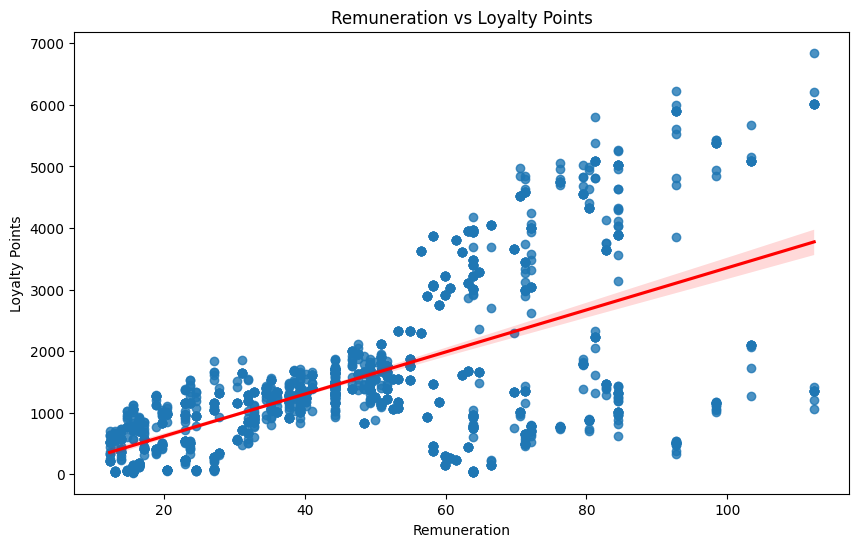

In [72]:
# Plot graph with regression line.
plt.figure(figsize=(10, 6))
sns.regplot(x=X_rem, y=y_rem, line_kws={"color": "red"})
plt.title('Remuneration vs Loyalty Points')
plt.xlabel('Remuneration')
plt.ylabel('Loyalty Points')
plt.show()

### 5.2.3 Histogram plot of Renumeration vs loyalty model residuals

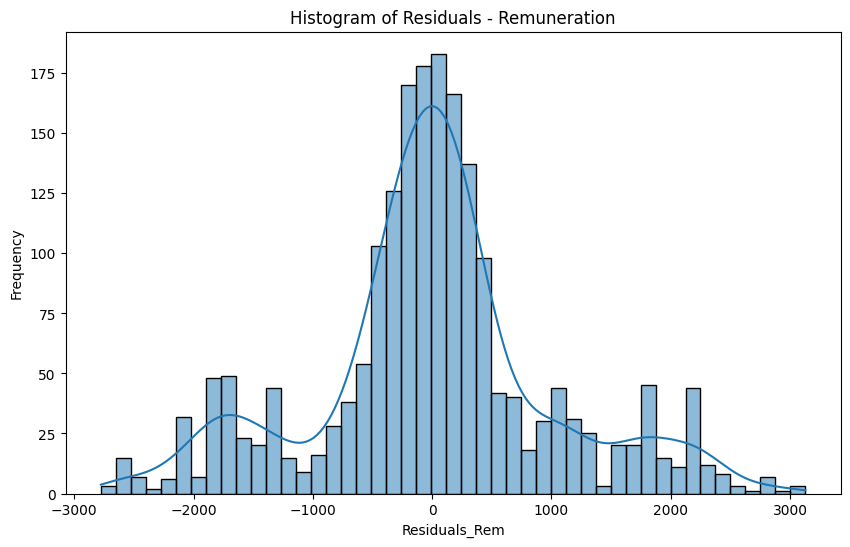

In [73]:
# Histogram plot of Remunerationregression residuals 

residuals = model_rem.resid
plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True)
plt.title('Histogram of Residuals - Remuneration')
plt.xlabel('Residuals_Rem')
plt.ylabel('Frequency')
plt.show()

### 5.3 age vs loyalty

In [74]:
# Define independent variable.
X_age = turtle_df['age']

# Define dependent variable.
y_age = turtle_df['loyalty_points']

# Create model and print summary of metrics.
model_age = ols('loyalty_points ~ age', data=turtle_df).fit()
print(model_age.summary())

                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     3.606
Date:                Wed, 31 Dec 2025   Prob (F-statistic):             0.0577
Time:                        01:02:05   Log-Likelihood:                -17150.
No. Observations:                2000   AIC:                         3.430e+04
Df Residuals:                    1998   BIC:                         3.431e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1736.5177     88.249     19.678      0.0

In [75]:
# Extract the estimated parameters.
params_age = model_age.params
print(params_age)

# Extract the standard errors.
errors_age = model_age.bse
print(errors_age)

# Extract the predicted values.
predictions_age = model_age.predict(X_age)
print(predictions_age)

Intercept    1736.517739
age            -4.012805
dtype: float64
Intercept    88.248731
age           2.113177
dtype: float64
0       1664.287247
1       1644.223221
2       1648.236026
3       1636.197611
4       1604.095169
           ...     
1995    1588.043949
1996    1563.967118
1997    1600.082364
1998    1600.082364
1999    1608.107975
Length: 2000, dtype: float64


In [76]:
# Set the X coefficient and the constant to generate the regression table.
x_coeff_age = params_age.iloc[1]
const_age = params_age.iloc[0]
errors_age_value = errors_age.iloc[1]

# View the output.
reg_output_age = {
    'Constant': const_age,
    'X Coefficient': x_coeff_age,
    'Error Terms': errors_age_value
}
print(reg_output_age)
print(model_age.summary())

{'Constant': 1736.517739399062, 'X Coefficient': -4.012805149995199, 'Error Terms': 2.113176887643077}
                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     3.606
Date:                Wed, 31 Dec 2025   Prob (F-statistic):             0.0577
Time:                        01:02:09   Log-Likelihood:                -17150.
No. Observations:                2000   AIC:                         3.430e+04
Df Residuals:                    1998   BIC:                         3.431e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------

In [77]:
# want to see prediction errors and the generalizability of the model

# r2_score is used below; import it from sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import r2_score, mean_absolute_error

X_train_age, X_test_age, y_train_age, y_test_age = train_test_split(
    X_age, y_age, test_size=0.2, random_state=41)

### 5c Simple Regression Model - Spend vs Loyalty Points
# add constant for intercept term
X_train_age = sm.add_constant(X_train_age)

# Use statsmodels.api.OLS for array-like inputs (ols with formula expects a DataFrame and a formula string)
model_age_train = sm.OLS(y_train_age, X_train_age).fit()

# Predict on the test set (remember to add constant)
X_test_age_const = sm.add_constant(X_test_age)
y_pred_age = model_spend_train.predict(X_test_age_const)

# Print the summary statistics
print("Training Set Regression Results:")
print(model_age_train.summary())
print('------------------------------------------------------------')

# print the rsquared values and compare
print('Rsquared for train set:  ', model_age_train.rsquared)
print('Rsquared for test set:  ', r2_score(y_test_age, y_pred_age))
print('------------------------------------------------------------')

# Calculate Mean Squared Error, Mean Absolute error and Root Mean Squared Error
from sklearn.metrics import mean_squared_error

print(f'Mean Squared Error on Test Set: {mean_squared_error(y_test_age, y_pred_age)}')
print(f'Mean Absolute Error on Test Set: {mean_absolute_error(y_test_age, y_pred_age)}')
print(f'Root Mean Squared Error on Test Set: {np.sqrt(mean_squared_error(y_test_age, y_pred_age))}')

Training Set Regression Results:
                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.706
Date:                Wed, 31 Dec 2025   Prob (F-statistic):              0.192
Time:                        01:02:12   Log-Likelihood:                -13697.
No. Observations:                1600   AIC:                         2.740e+04
Df Residuals:                    1598   BIC:                         2.741e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1701.75

### 5.3.1 Heteroskedasticity of age vs loyalty model

In [78]:
# checking for the heteroskedasticity
import statsmodels.stats.api as sms
import statsmodels.api as sm
from statsmodels.formula.api import ols

# conducting the brauch Pagan Test

bp_test_age = sms.het_breuschpagan(model_age.resid, model_age.model.exog)
labels = ['Lagrange multiplier statistic', 'p-value', 
          'f-value', 'f p-value']
print(dict(zip(labels, bp_test_age)))

{'Lagrange multiplier statistic': 13.045150861306531, 'p-value': 0.00030407066519269317, 'f-value': 13.117666680845232, 'f p-value': 0.00029981923558023614}


### 5.3.1  Age vs loyalty model plot

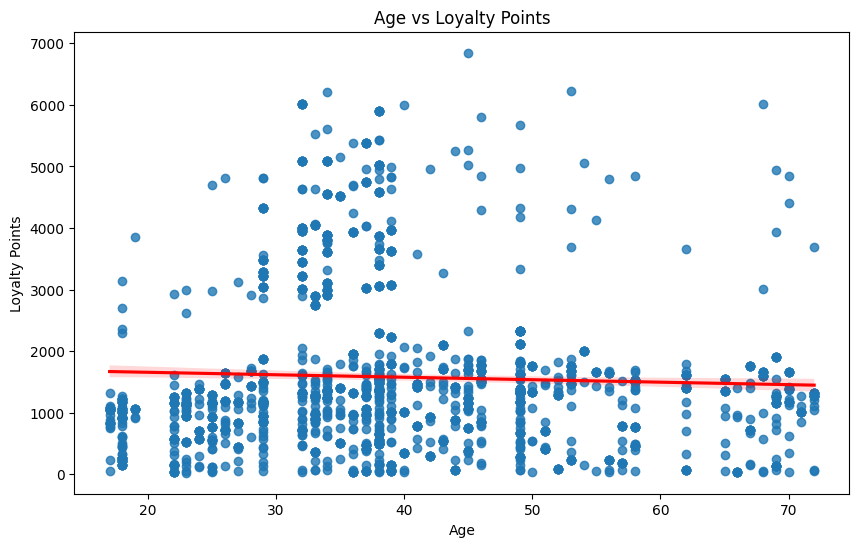

In [79]:
# Plot graph with regression line.
plt.figure(figsize=(10, 6))
sns.regplot(x=X_age, y=y_age, line_kws={"color": "red"})
plt.title('Age vs Loyalty Points')
plt.xlabel('Age')
plt.ylabel('Loyalty Points')
plt.show()

### 5.3.2  Histogram plot of Age vs loyalty model residuals

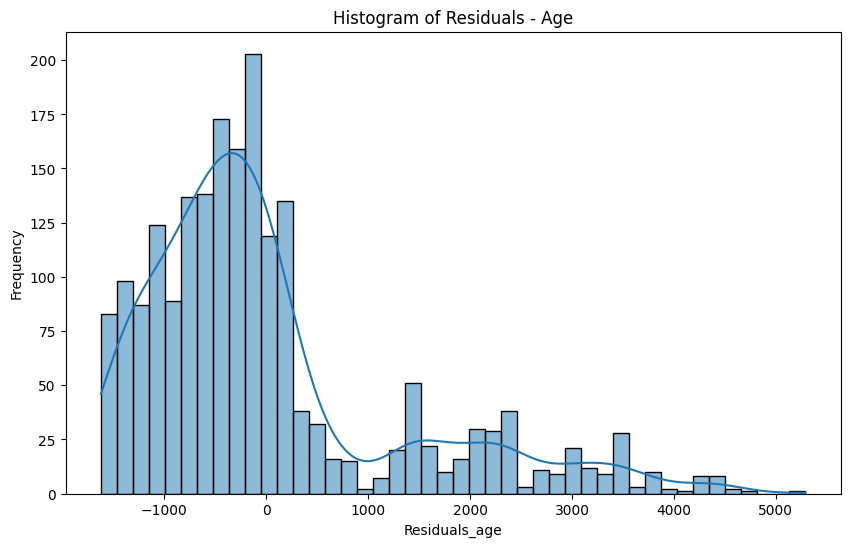

In [80]:
# Histogram plot of the age regression residuals

residuals = model_age.resid
plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True)
plt.title('Histogram of Residuals - Age')
plt.xlabel('Residuals_age')
plt.ylabel('Frequency')
plt.show()

## 6 Multiple Regression Model


In [81]:
# Full Multiple Regression Model

X_mlr = turtle_df[['age', 'spending_score', 'remuneration']]
y_mlr = turtle_df['loyalty_points']


model_mlr = ols('loyalty_points ~ age + remuneration + spending_score', data=turtle_df).fit()


### 6.1 Multiple Regression Model Output Table

In [82]:
# Setting up a multiple regression output table

const_mlr = model_mlr.params.iloc[0]
x_coeff_1_mlr = model_mlr.params.iloc[1]
x_coeff_2_mlr = model_mlr.params.iloc[2]
x_coeff_3_mlr = model_mlr.params.iloc[3]
errors_mlr = model_mlr.bse.iloc[1]

reg_output_mlr = {
    'Constant': const_mlr,
    'X Coefficient Age': x_coeff_1_mlr,
    'X Coefficient Remuneration': x_coeff_2_mlr,
    'X Coefficient Spending Score': x_coeff_3_mlr,
    'Error Terms': errors_mlr}

print(reg_output_mlr)

{'Constant': -2203.059751307897, 'X Coefficient Age': 11.060658711843319, 'X Coefficient Remuneration': 34.008385492602436, 'X Coefficient Spending Score': 34.18319657763365, 'Error Terms': 0.8688447566513112}


In [83]:
# Standard MLR summary table

print(model_mlr.summary())

                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.840
Model:                            OLS   Adj. R-squared:                  0.840
Method:                 Least Squares   F-statistic:                     3491.
Date:                Wed, 31 Dec 2025   Prob (F-statistic):               0.00
Time:                        01:02:27   Log-Likelihood:                -15320.
No. Observations:                2000   AIC:                         3.065e+04
Df Residuals:                    1996   BIC:                         3.067e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept      -2203.0598     52.361    -42.

In [84]:
# want to see prediction errors and the generalizability of the model

# r2_score and mean_absolute_error are used below; import them from sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

X_train_mlr, X_test_mlr, y_train_mlr, y_test_mlr = train_test_split(
    X_mlr, y_mlr, test_size=0.2, random_state=41)

### 5c Simple Regression Model - Spend vs Loyalty Points
# add constant for intercept term
X_train_mlr = sm.add_constant(X_train_mlr)

# Use statsmodels.api.OLS for array-like inputs (ols with formula expects a DataFrame and a formula string)
model_mlr_train = sm.OLS(y_train_mlr, X_train_mlr).fit()

# Predict on the test set (remember to add constant)
X_test_mlr_const = sm.add_constant(X_test_mlr)
y_pred_mlr = model_mlr_train.predict(X_test_mlr_const)

# Print the summary statistics
print("Training Set Regression Results:")
print(model_mlr_train.summary())
print('------------------------------------------------------------')

# print the rsquared values and compare
print('Rsquared for train set:  ', model_mlr_train.rsquared)
print('Rsquared for test set:  ', r2_score(y_test_mlr, y_pred_mlr))
print('------------------------------------------------------------')

# Calculate Mean Squared Error, Mean Absolute error and Root Mean Squared Error
from sklearn.metrics import mean_squared_error

print(f'Mean Squared Error on Test Set: {mean_squared_error(y_test_mlr, y_pred_mlr)}')
print(f'Mean Absolute Error on Test Set: {mean_absolute_error(y_test_mlr, y_pred_mlr)}')
print(f'Root Mean Squared Error on Test Set: {np.sqrt(mean_squared_error(y_test_mlr, y_pred_mlr))}')

Training Set Regression Results:
                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.840
Model:                            OLS   Adj. R-squared:                  0.839
Method:                 Least Squares   F-statistic:                     2784.
Date:                Wed, 31 Dec 2025   Prob (F-statistic):               0.00
Time:                        01:02:29   Log-Likelihood:                -12234.
No. Observations:                1600   AIC:                         2.448e+04
Df Residuals:                    1596   BIC:                         2.450e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const      

### 6.1 Histogram plot of MLR model residuals

In [85]:
# checking for the heteroskedasticity
import statsmodels.stats.api as sms
import statsmodels.api as sm
from statsmodels.formula.api import ols

# conducting the brauch Pagan Test

bp_test_mlr = sms.het_breuschpagan(model_mlr.resid, model_mlr.model.exog)
labels = ['Lagrange multiplier statistic', 'p-value', 
          'f-value', 'f p-value']
print(dict(zip(labels, bp_test_mlr)))

{'Lagrange multiplier statistic': 43.32213737472168, 'p-value': 2.102379354381326e-09, 'f-value': 14.730918470133524, 'f p-value': 1.7293587945215046e-09}


### 6.1 Resiudals vs Fitted plot of MLR model 

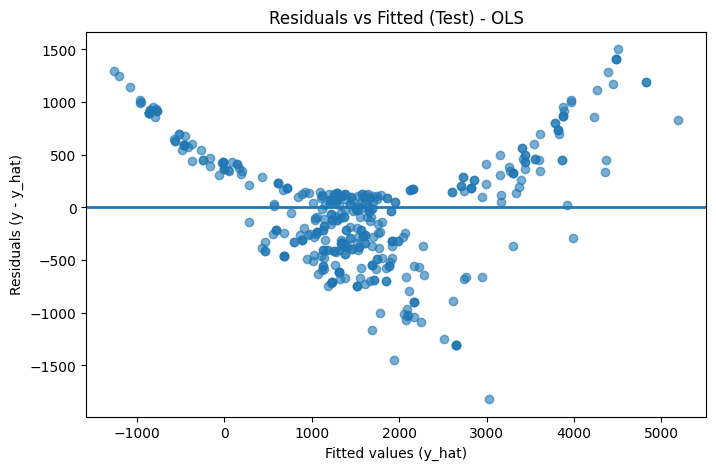

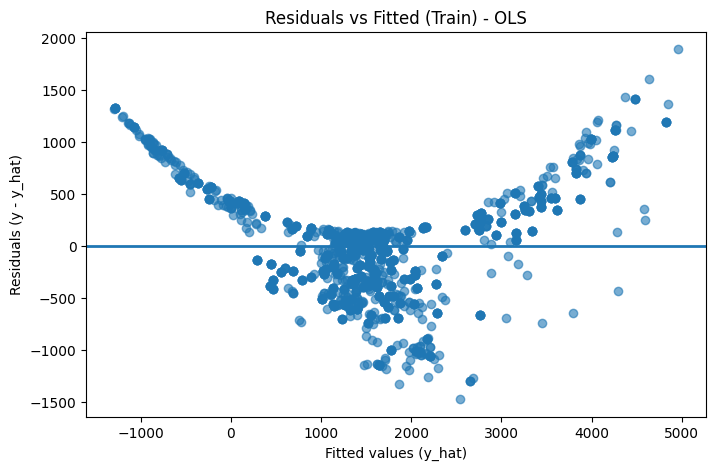

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# 1) Residuals vs Fitted (TEST)
resid_test = y_test_mlr - y_pred_mlr

plt.figure(figsize=(8,5))
plt.scatter(y_pred_mlr, resid_test, alpha=0.6)
plt.axhline(0, linewidth=2)
plt.title("Residuals vs Fitted (Test) - OLS")
plt.xlabel("Fitted values (y_hat)")
plt.ylabel("Residuals (y - y_hat)")
plt.show()

# 2) Residuals vs Fitted (TRAIN)
yhat_train = model_mlr_train.predict(X_train_mlr)
resid_train = y_train_mlr - yhat_train

plt.figure(figsize=(8,5))
plt.scatter(yhat_train, resid_train, alpha=0.6)
plt.axhline(0, linewidth=2)
plt.title("Residuals vs Fitted (Train) - OLS")
plt.xlabel("Fitted values (y_hat)")
plt.ylabel("Residuals (y - y_hat)")
plt.show()


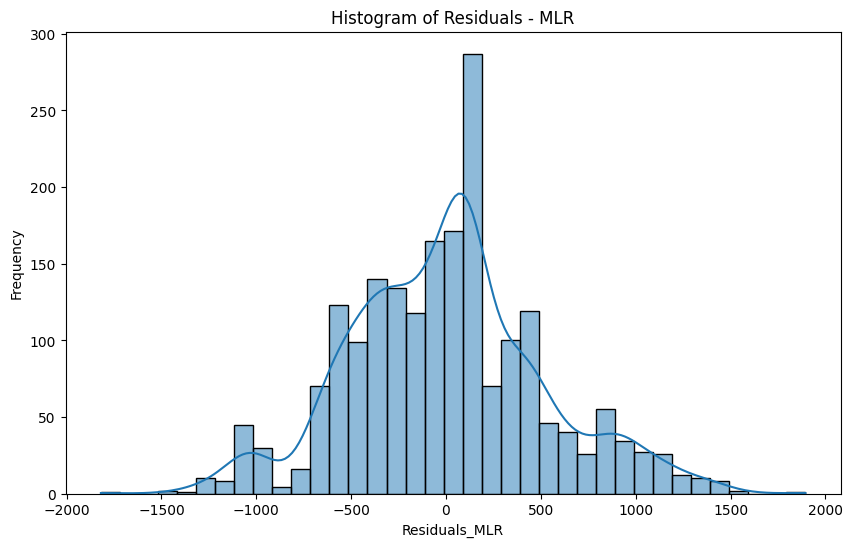

In [56]:
# Histogram plot of the age regression residuals

residuals = model_mlr.resid
plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True)
plt.title('Histogram of Residuals - MLR')
plt.xlabel('Residuals_MLR')
plt.ylabel('Frequency')
plt.show()

## 6. Observations and insights

## About the dataset 

The dataset has **~2,000 customer records** and **11 variables**, split into:

- **Categorical:** gender, education, language, platform, review, subject/summary 
- **Numerical:** age, remuneration, spending_score , loyalty_points, product 

- `info()` function confirmed **no missing values** across any columns.  
- `fillna(0)` function as a precaution to fill missing values with 0.

## Pure inspection — distributions (what the plots suggest)

- **Age:** roughly unimodal around **36–39**, slight right tail, no obvious extreme outliers.  
  *On its own*, this doesn’t tell us about heteroskedasticity — we still need residual checks.

- **Remuneration:** clearly **right-skewed**, looks **segmented / near bi-modal** (one group ~15–25k£, larger group ~40–60k£).  
  This is a **red flag** for uneven variance, but it **doesn’t prove** heteroskedasticity.

- **Spending_score:** **multi-modal** (rough groups near **0–20**, **40–60**, **70–80**).  
  This hints at natural customer segments rather than one smooth bell curve.

- **Loyalty_points (target):** strongly **right-skewed** with high-value customers that behave like outliers.  
  This raises the risk of **non-normal residuals** and **variance increasing** for high-loyalty customers.

## Correlations + regression checks (what we can infer)

A correlation heatmap shows **predictors aren’t strongly correlated with each other**, so multicollinearity is not a major concern.  
But each predictor shows **meaningful association** with `loyalty_points`, so they are reasonable candidates.

From the regression graphs/tables:

- **Age vs loyalty:** weak relationship (near-flat fit, low \(R^2\)); age is not useful as a *standalone* driver.
- **Remuneration / spending vs loyalty:** moderate relationship, but scatter increases at higher values.
- **MLR (age + remuneration + spending):** much stronger fit (high \(R^2\), better RMSE/MAE), but residual plots still show **structure/curvature** and BP suggests **heteroskedasticity**.

So overall: **prediction improves when we combine variables**, but the **constant-variance assumption is violated**, meaning standard errors / t-stats / p-values from plain OLS should be treated with caution.


# Week 2 assignment: Exploring the structure using decision trees.

The team wants you to use decision trees to attempt to better understand the structure found in the data. You need to grow and prune a decision tree regressor and then visualise and interpret the output.
Make sure to comment on the potential usefulness in decision-making processes and your observations regarding the model.

## Instructions
1. Prepare the data for creating your decision tree. 
    1. Import the CSV file you have prepared in Week 1.
    2. Create a new DataFrame with the appropriate columns.
        1. Specify that loyalty points is the target variable (Y) and should be excluded from your input data.
        2. Specify X for the independent variables and y as the dependent variable. Therefore, df\[cols\] will be the independent variables and the column containing loyalty points the dependent variable.
        3. Explore the new DataFrame. 
2. Split the data set into a train and test sets for both X and y at a 70:30 ratio. As previously, random_state=42.
3. Create a decision tree regressor to explore the impact of other features on the loyalty points.
    1. Import the DecisionTreeRegressor class from the sklearn.tree library. 
    2. Create a variable (e.g. regressor) to store the DecisionTreeRegressor() class. (As previously, random_state=42.).
    3. Fit the regressor object to the data set with the fit() function.
    4. Remember to prune your tree using basic pruning strategies and compare the performance before and after applying the pruning strategy.
    5. Plot the final decision tree.
4. Fit a final model and interpret the output.
    1. Justify your selection of pruning strategy implemented and interpret the output.
    2. Evaluate the usefulness of the obtained result and interpret the tree and how it could be used to inform business decisions in the organisation.
5. Summarise (150–200 words) the most important business insights, anything you would like to explore further, and suggested future actions.
 
Back up your work to a safe location. This will allow you to revert to a previous state in the case of making a mistake in the code or deleting a section by mistake. (A simple way of doing this is to save or email a compressed version to yourself at frequent intervals.)



## 1. Load and prepare the data

In [25]:
# Import all the necessary packages
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, plot_tree 
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import classification_report
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split,cross_val_score,KFold
import statsmodels.api as sm
import warnings
import matplotlib.pyplot as plt

# Settings for the notebook.
warnings.filterwarnings("ignore")
plt.rcParams['figure.figsize'] = [15, 10]

In [26]:
# Create your new DataFrame.

df = pd.read_csv('turtle_reviews_cleaned.csv')


In [27]:
# Specify Y.

y = df['loyalty_points']

# Specify X.
X = df[['age', 'remuneration', 'spending_score']]

In [28]:
# Review X and Y.

#Basic info of X
#1. Null values, data types, memory usage, number of entries etc.
print(X.info())
#2. Mean, median, mode, standard deviation, min, max, quartiles etc.
print(X.describe())
#3. Mean, median, mode, standard deviation, min, max, quartiles etc.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2000 non-null   int64  
 1   remuneration    2000 non-null   float64
 2   spending_score  2000 non-null   int64  
dtypes: float64(1), int64(2)
memory usage: 47.0 KB
None
               age  remuneration  spending_score
count  2000.000000   2000.000000     2000.000000
mean     39.495000     48.079060       50.000000
std      13.573212     23.123984       26.094702
min      17.000000     12.300000        1.000000
25%      29.000000     30.340000       32.000000
50%      38.000000     47.150000       50.000000
75%      49.000000     63.960000       73.000000
max      72.000000    112.340000       99.000000


In [29]:

#Basic info of y
#1. Null values, data types, memory usage, number of entries etc.
print(y.info())
#2. Mean, median, mode, standard deviation, min, max, quartiles etc.
print(y.describe())
#3. Mean, median, mode, standard deviation, min, max, quartiles etc.

<class 'pandas.core.series.Series'>
RangeIndex: 2000 entries, 0 to 1999
Series name: loyalty_points
Non-Null Count  Dtype
--------------  -----
2000 non-null   int64
dtypes: int64(1)
memory usage: 15.8 KB
None
count    2000.000000
mean     1578.032000
std      1283.239705
min        25.000000
25%       772.000000
50%      1276.000000
75%      1751.250000
max      6847.000000
Name: loyalty_points, dtype: float64


## 2. Create train and test data sets.

In [30]:
# Split the data into test and train data.


X_train, X_intermediate, y_train, y_intermediate = train_test_split(
    X, y, test_size=0.30, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_intermediate, y_intermediate, test_size=0.50, random_state=42
)

## 3. Create Decision tree regressor (Initial version)

In [31]:

num_features = ["age", "remuneration", "spending_score"]
cat_features = ["gender", "education"]



# Create your decision tree regressor.

dtr = DecisionTreeRegressor(criterion='squared_error',
                             max_depth=4,
                             random_state=1)

# Train the decision tree regressor.
dtr = dtr.fit(X_train, y_train) 

# Predict the response for the test data set.
y_pred = dtr.predict(X_test)  

### 3.1 Print the performance metrics

In [32]:

# Evaluate the model.
# Use the test set (y_test) to match y_pred (predictions on X_test).
mae_dtr = mean_absolute_error(y_test, y_pred)
rmse_dtr = np.sqrt(mean_squared_error(y_test, y_pred))
r2_dtr = r2_score(y_test, y_pred)

print(f"MAE: {mae_dtr:.4f}, RMSE: {rmse_dtr:.4f}, R2: {r2_dtr:.4f}")

MAE: 216.5881, RMSE: 309.0704, R2: 0.9439


## 4. Performing CV to estimate the best parameters for the Tree Regressor

In [33]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)


candidate_params = [
    {"max_depth": d, "min_samples_leaf": l, "min_samples_split": s}
    for d in range(1, 7)
    for l in [1, 2, 5, 10, 20]
    for s in [2, 5, 10, 20]
]



rows = []
for p in candidate_params:
    
    model = DecisionTreeRegressor(random_state=42, **p)

    # cross_val_score returns NEGATIVE MAE for this scoring; flip sign back
    cv_mae = -cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    # RMSE (use neg_root_mean_squared_error if available)
    cv_rmse = -cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="neg_root_mean_squared_error"
    )

    # R2
    cv_r2 = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="r2"
    )

    rows.append({
        "Parameters": p,
        "CV_MAE_mean": cv_mae.mean(),   "CV_MAE_std": cv_mae.std(),
        "CV_RMSE_mean": cv_rmse.mean(), "CV_RMSE_std": cv_rmse.std(),
        "CV_R2_mean": cv_r2.mean(),     "CV_R2_std": cv_r2.std()
    })

param_metrics_cv = pd.DataFrame(rows).sort_values("CV_MAE_mean", ascending=True)




### 4.1 Listing the best tree regressor parameters from CV

In [ ]:
print("\nTop 10 parameter sets by CV MAE (train only):")
print(param_metrics_cv.head(10))

param_metrics_cv.to_csv("decision_tree_param_tuning_metrics_cv_mae.csv", index=False)

best_params = param_metrics_cv.iloc[0]["Parameters"]
print("\nBest Parameters (by CV MAE):", best_params)





Top 10 parameter sets by CV MAE (train only):
                                            Parameters  CV_MAE_mean  \
110  {'max_depth': 6, 'min_samples_leaf': 5, 'min_s...   140.013149   
109  {'max_depth': 6, 'min_samples_leaf': 5, 'min_s...   140.013149   
108  {'max_depth': 6, 'min_samples_leaf': 5, 'min_s...   140.013149   
104  {'max_depth': 6, 'min_samples_leaf': 2, 'min_s...   140.118007   
105  {'max_depth': 6, 'min_samples_leaf': 2, 'min_s...   140.271221   
100  {'max_depth': 6, 'min_samples_leaf': 1, 'min_s...   140.466765   
101  {'max_depth': 6, 'min_samples_leaf': 1, 'min_s...   140.615694   
115  {'max_depth': 6, 'min_samples_leaf': 10, 'min_...   141.272769   
114  {'max_depth': 6, 'min_samples_leaf': 10, 'min_...   141.272769   
113  {'max_depth': 6, 'min_samples_leaf': 10, 'min_...   141.272769   

     CV_MAE_std  CV_RMSE_mean  CV_RMSE_std  CV_R2_mean  CV_R2_std  
110    8.558570    207.675985    19.176020    0.973236   0.006830  
109    8.558570    207.675985    19

## 5. Performing Bootstrapped Feature Stability


In [35]:
from sklearn.utils import resample

X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

B = 30
imps = []

for b in range(B):
    Xb, yb = resample(X_trainval, y_trainval, replace=True, random_state=42 + b)
    m = DecisionTreeRegressor(random_state=42, **best_params)
    m.fit(Xb, yb)
    imps.append(m.feature_importances_)

imps = np.array(imps)

stability_table = (
    pd.DataFrame({
        "Feature": X.columns,
        "Importance - Mean": imps.mean(axis=0),
        "Importance - Std": imps.std(axis=0)
    })
    .sort_values("Importance - Mean", ascending=False)
)

print("\nFeature importance stability (BootStrap Samples):")
print(stability_table)




Feature importance stability (BootStrap Samples):
          Feature  Importance - Mean  Importance - Std
2  spending_score            0.50945          0.053587
1    remuneration            0.48015          0.054091
0             age            0.01040          0.003180


## 6. Performing Permutation Importance

In [36]:


from sklearn.inspection import permutation_importance
kf = KFold(n_splits=5, shuffle=True, random_state=42)

all_fold_imps = []

for fold, (tr_idx, va_idx) in enumerate(kf.split(X_trainval), start=1):
    Xtr, Xva = X_trainval.iloc[tr_idx], X_trainval.iloc[va_idx]
    ytr, yva = y_trainval.iloc[tr_idx], y_trainval.iloc[va_idx]

    m = DecisionTreeRegressor(random_state=42, **best_params)
    m.fit(Xtr, ytr)

    # permutation importance computed on the fold's validation split
    perm = permutation_importance(
        m, Xva, yva,
        n_repeats=20,
        random_state=42,
        scoring="neg_mean_absolute_error"
    )

    # Convert to ΔMAE (positive = worse MAE after shuffling = important)
    fold_imp = perm.importances_mean  # already in "score units"; with neg MAE scoring, this becomes Δ(-MAE)
    # For neg MAE, higher score is better; shuffling reduces score => negative changes.
    # Convert to ΔMAE directly by negating:
    fold_delta_mae = -fold_imp

    all_fold_imps.append(fold_delta_mae)

all_fold_imps = np.array(all_fold_imps)  # shape: (n_folds, n_features)

perm_imp_cv = pd.DataFrame({
    "Feature": X.columns,
    "PermImp_DeltaMAE_Mean": all_fold_imps.mean(axis=0),
    "PermImp_DeltaMAE_Std": all_fold_imps.std(axis=0),
}).sort_values("PermImp_DeltaMAE_Mean", ascending=False)

print("\nCV Permutation Importance (ΔMAE mean ± std):")
print(perm_imp_cv)





CV Permutation Importance (ΔMAE mean ± std):
          Feature  PermImp_DeltaMAE_Mean  PermImp_DeltaMAE_Std
0             age             -49.717996              9.488964
1    remuneration            -607.306008             44.526050
2  spending_score            -835.753984             39.104510


## 8. Refit on final model & evaluate on Test

In [37]:
# -----------------------------
# 3) Refit final model on Train+Val, evaluate once on Test
# -----------------------------


final_model = DecisionTreeRegressor(random_state=42, **best_params)
final_model.fit(X_trainval, y_trainval)

yhat_trainval = final_model.predict(X_trainval)
yhat_test = final_model.predict(X_test)

print("\nFinal Train+Val MAE:", mean_absolute_error(y_trainval, yhat_trainval))
print("Final Train+Val RMSE:", np.sqrt(mean_squared_error(y_trainval, yhat_trainval)))
print("Final Train+Val R2  :", r2_score(y_trainval, yhat_trainval))
print("Final Test MAE     :", mean_absolute_error(y_test, yhat_test))
print("Final Test RMSE    :", np.sqrt(mean_squared_error(y_test, yhat_test)))
print("Final Test R2      :", r2_score(y_test, yhat_test))


Final Train+Val MAE: 138.2445835129382
Final Train+Val RMSE: 206.73639686610713
Final Train+Val R2  : 0.9738726321079164
Final Test MAE     : 137.7325164783258
Final Test RMSE    : 228.4791023006693
Final Test R2      : 0.9693244490786375


## 7. Fit and plot final model.

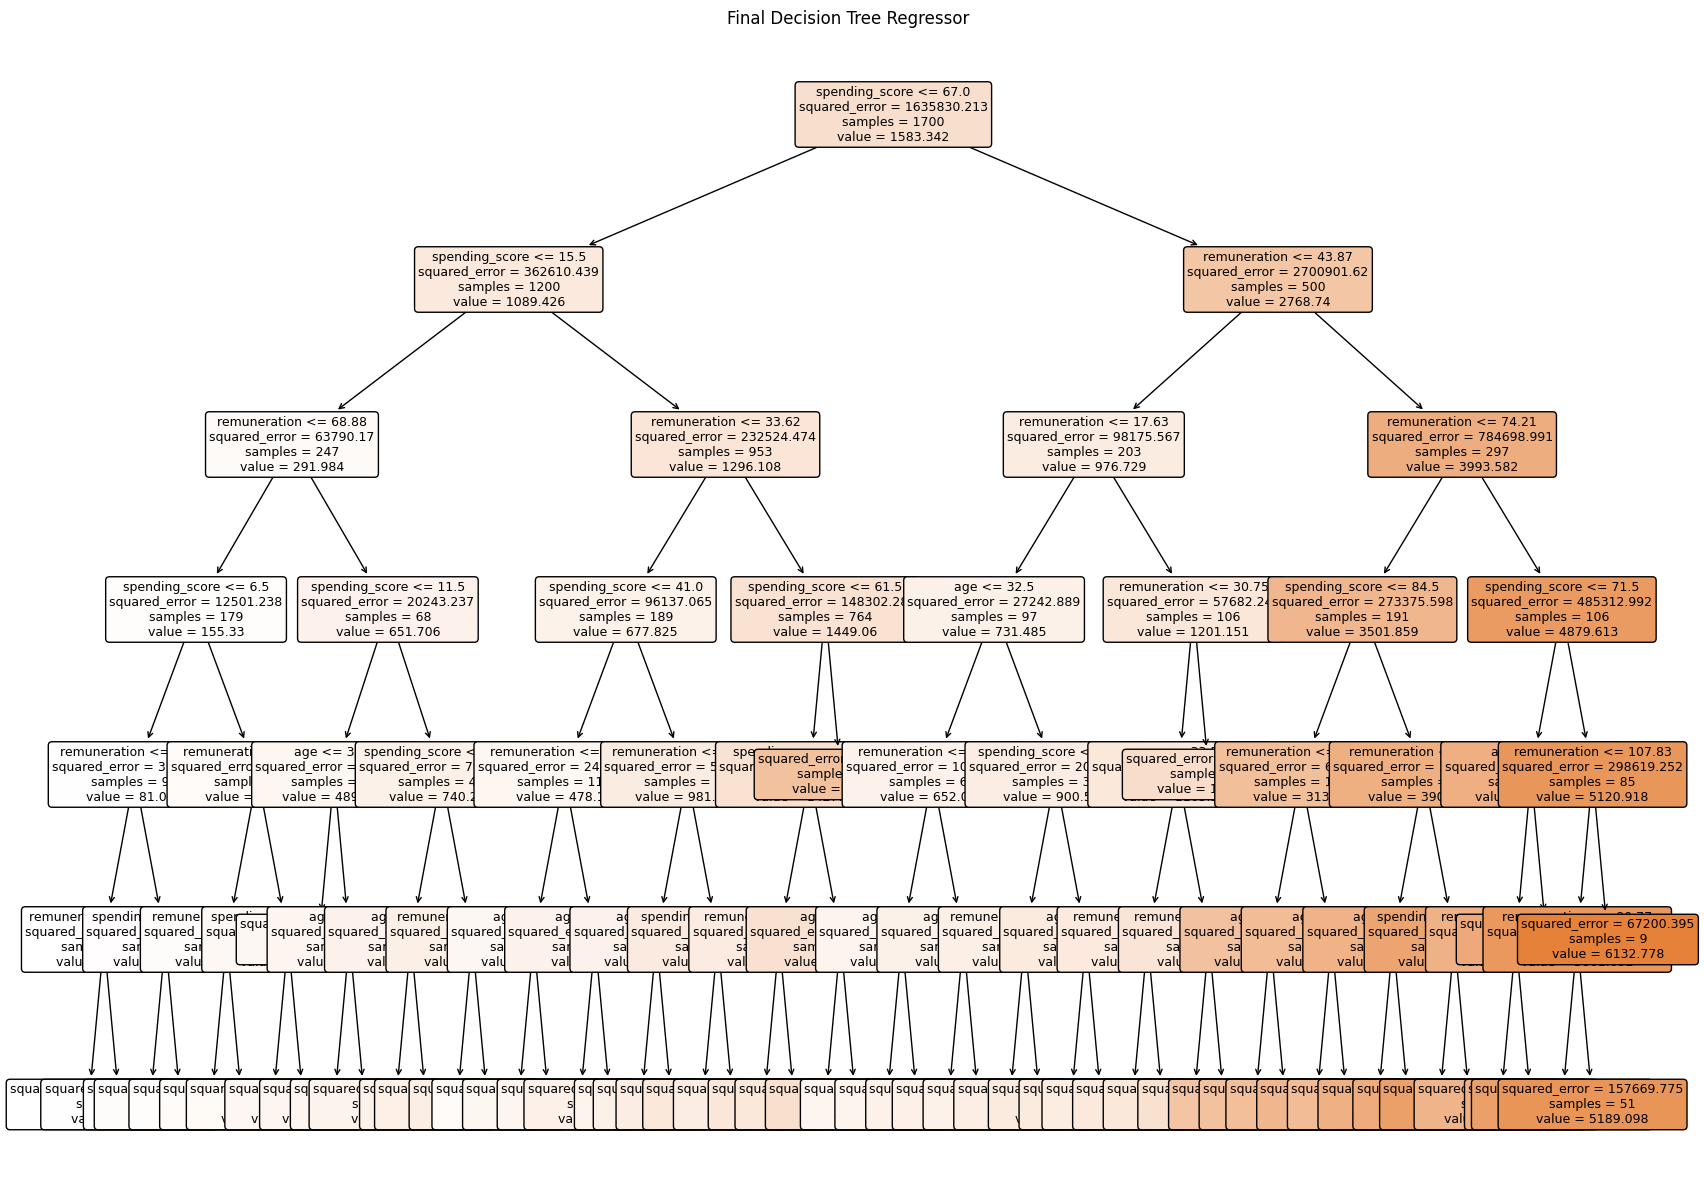

Tree depth: 6
Number of leaves: 55


remuneration      0.507767
spending_score    0.481868
age               0.010365
dtype: float64

Final Train MAE : 138.2445835129382
Final Train RMSE: 206.73639686610713
Final Train R2  : 0.9738726321079164
Final Test MAE : 137.7325164783258
Final Test RMSE: 228.4791023006693
Final Test R2  : 0.9693244490786375


In [39]:
# The Final Model as per the best parameters from above.

final_model = DecisionTreeRegressor(random_state=42, **best_params)
final_model.fit(X_trainval, y_trainval)

# Final Model plot

plt.figure(figsize=(20, 15))
plot_tree(
    final_model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=6,          # keeps plot readable; increase if you want
    fontsize=9
)
plt.title("Final Decision Tree Regressor")
plt.show()

# Tree Depth and number of leaves
print("Tree depth:", final_model.get_depth())
print("Number of leaves:", final_model.get_n_leaves())


# Feature importances (rough signal; trees can be unstable)
fi = pd.Series(final_model.feature_importances_, index=X.columns).sort_values(ascending=False)
display(fi.head(15))

# Final train performance
y_pred = final_model.predict(X_trainval)

print("Final Train MAE :", mean_absolute_error(y_trainval, y_pred))
print("Final Train RMSE:", np.sqrt(mean_squared_error(y_trainval, y_pred)))
print("Final Train R2  :", r2_score(y_trainval, y_pred))
# Final test performance
y_pred = final_model.predict(X_test)
print("Final Test MAE :", mean_absolute_error(y_test, y_pred))
print("Final Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Final Test R2  :", r2_score(y_test, y_pred))

## 8. Residual vs Fitted plot

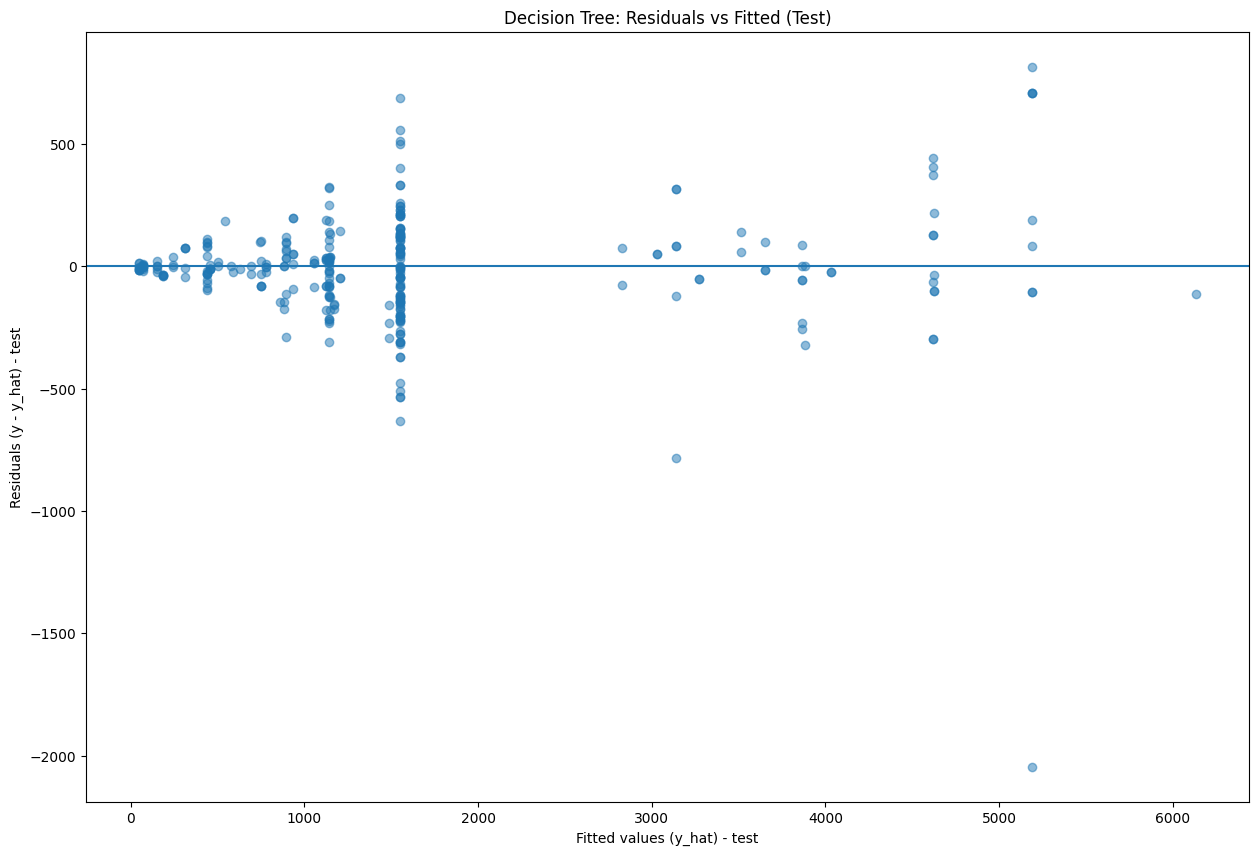

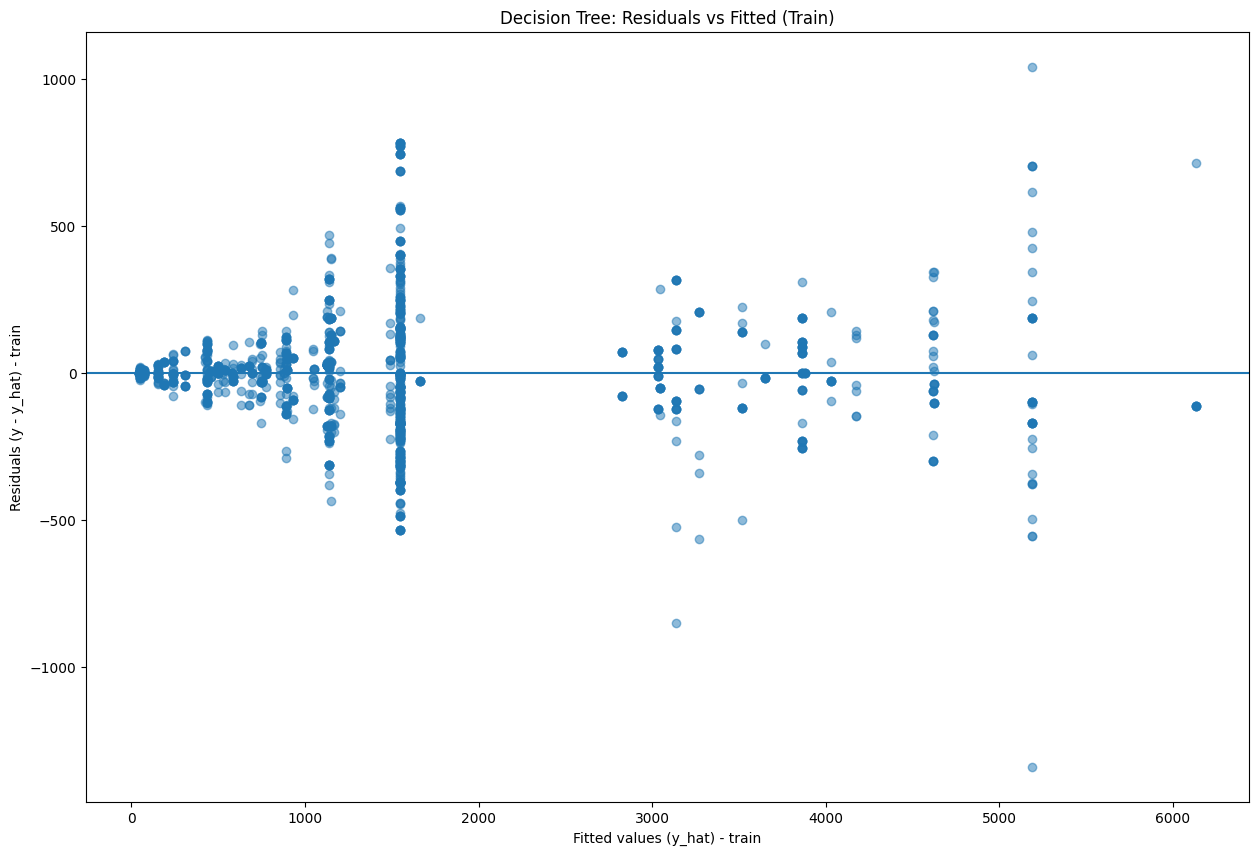

In [40]:

# predictions
yhat_train = final_model.predict(X_train)
yhat_test = final_model.predict(X_test)

# residuals
res_train = y_train - yhat_train
res_test = y_test - yhat_test

# Residuals vs Fitted (test)
plt.figure()
plt.scatter(yhat_test, res_test, alpha=0.5)
plt.axhline(0)
plt.xlabel("Fitted values (y_hat) - test")
plt.ylabel("Residuals (y - y_hat) - test")
plt.title("Decision Tree: Residuals vs Fitted (Test)")
plt.show()

# Optional: same for train
plt.figure()
plt.scatter(yhat_train, res_train, alpha=0.5)
plt.axhline(0)
plt.xlabel("Fitted values (y_hat) - train")
plt.ylabel("Residuals (y - y_hat) - train")
plt.title("Decision Tree: Residuals vs Fitted (Train)")
plt.show()

## 5. Discuss: Insights and observations

***Your observations here...***

## Interpret model and note observations

- The Decision Tree model shows good results, with **R²** values indicating a strong fit on both the training and test datasets.

- The **tree depth** and **number of leaves** are moderate, suggesting a balanced model that is **simple, interpretable**, and not overly complex.

- **Feature importance** indicates that `spending_score` is the most influential predictor of `loyalty_points`, followed by `remuneration`, and then `age`.

- The **residual plots** suggest the model captures the underlying patterns in the data well, with **no obvious systematic structure** remaining in the residuals—supporting that the model is appropriate for this dataset.

- Some residual patterns may appear as **vertical-line bands**. This can occur with decision trees due to their **threshold-based, piecewise-constant predictions**, which can create “stepped” prediction levels.

# 

# Week 3 assignment: Clustering with *k*-means using Python

The marketing department also wants to better understand the usefulness of renumeration and spending scores but do not know where to begin. You are tasked to identify groups within the customer base that can be used to target specific market segments. Use *k*-means clustering to identify the optimal number of clusters and then apply and plot the data using the created segments.

## Instructions
1. Prepare the data for clustering. 
    1. Import the CSV file you have prepared in Week 1.
    2. Create a new DataFrame (e.g. `df3`) containing the `renumeration` and `spending_score` columns.
    3. Explore the new DataFrame. 
2. Plot the renumeration versus spending score.
    1. Create a scatterplot.
    2. Create a pairplot.
3. Use the Silhouette and Elbow methods to determine the optimal number of clusters for *k*-means clustering.
    1. Plot both methods and explain how you determine the number of clusters to use.
    2. Add titles and legends to the plot.
4. Evaluate the usefulness of at least three values for *k* based on insights from the Elbow and Silhoutte methods.
    1. Plot the predicted *k*-means.
    2. Explain which value might give you the best clustering.
5. Fit a final model using your selected value for *k*.
    1. Justify your selection and comment on the respective cluster sizes of your final solution.
    2. Check the number of observations per predicted class.
6. Plot the clusters and interpret the model.

## 1. Load and explore the data

In [109]:
# Import necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import accuracy_score
from scipy.spatial.distance import cdist

import warnings
warnings.filterwarnings('ignore')

In [110]:
# Load the CSV file(s) as df2.

df2 = pd.read_csv('turtle_reviews_cleaned.csv')


# View DataFrame.
df2.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on the screen itself is at an absolute premium. The fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless. The only reason that I gave it 2 stars and not 1 was that, technically speaking, it can at least still stand up to block your notes and dice rolls. Other than that, it drops the ball completely.",The fact that 50% of this space is wasted on art (and not terribly informative or needed art ...
1,Male,23,12.30,81,524,graduate,466,"An Open Letter to GaleForce9*:\n\nYour unpainted miniatures are very not bad. Your spell cards are great. Your board games are ""meh"". Your DM screens, however, are freaking terrible. I'm still waiting for a single screen that isn't polluted with pointless artwork where useful, reference-able tables should be. Once again, you've created a single use screen that is only useful when running the ""Storm King's Thunder"" adventure. Even despite the fact that it's geared to that adventure path, it's usefulness negligible, at best. I massive swath of the inner panel is wasted on artwork and a bloated overland map, which could have been easily reduced to a single panel in size. And the few table you have are nigh-useless themselves.\n\nIn short, stop making crap DM screens.",Another worthless Dungeon Master's screen from GaleForce9
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are filled with a general Forgotten Realms map is beyond me. Most of one of them is all blue ocean. Such a waste.\n\nI don't understand why they can't make these DM Screens more useful for these ""kinds of adventures"" rather than solely the specific adventure. You're supposed to be able to transpose this adventure to other lands outside the Forgotten Realms. So even just a list of new monsters or NPCs would at least be useful than the map. Even more would just be stuff related to running the game but broad-use stuff related to giants.\n\nSame thing with Curse of Strahd. Why not make it useful for raven loft, undead or horror campaigns in general... instead a huge amount of screen space is solely mapping out Castle Ravenloft, which is only useful during a small fraction of the time even for the Curse of Strahd adventure, let alone various other Ravenloft adventuring.\n\nThey really kill the extended use of these screens by not thinking about their potential use, both for the adventure in question, as well as use in a broader sense.\n\nThe Rage of Demons screen is far more useful for broad under dark adventuring - covering a lot of rules for the various conditions you may suffer... and the map is only one panel.\n\nThis Storm Giants one is decent for a few tables it includes - but really misses the mark. Maybe they should ask a few DMs what they would use?","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new dm and it's perfect!,Five Stars
4,Female,33,13.94,40,366,graduate,291,"As my review of GF9's previous screens these were completely unnecessary and nearly useless. Skip them, this is the definition of a waste of money.",Money trap


In [111]:
# Drop unnecessary columns.
df3 = df2[['remuneration', 'spending_score']]

# View DataFrame.
df3.head()


,remuneration,spending_score
0,12.30,39
1,12.30,81
2,13.12,6
3,13.12,77
4,13.94,40


In [112]:
# Explore the data.
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   remuneration    2000 non-null   float64
 1   spending_score  2000 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 31.4 KB


In [113]:
# Descriptive statistics.
df3.describe()

,remuneration,spending_score
count,2000.000000,2000.000000
mean,48.079060,50.000000
std,23.123984,26.094702
min,12.300000,1.000000
25%,30.340000,32.000000
50%,47.150000,50.000000
75%,63.960000,73.000000
max,112.340000,99.000000


## 2. Plot

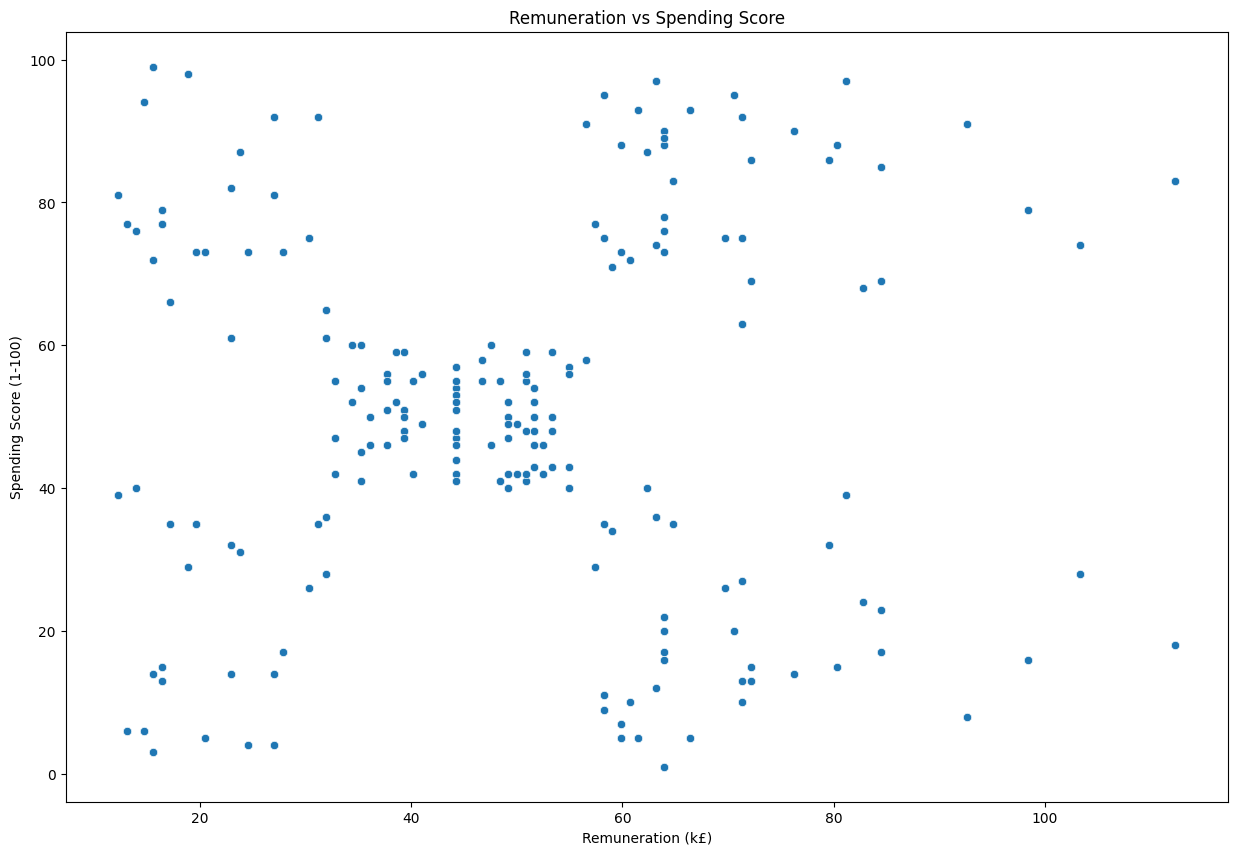

In [114]:
# Create a scatterplot with Seaborn.
sns.scatterplot(data=df3, x='remuneration', y='spending_score')
plt.title('Remuneration vs Spending Score')
plt.xlabel('Remuneration (k£)')
plt.ylabel('Spending Score (1-100)')
plt.show()


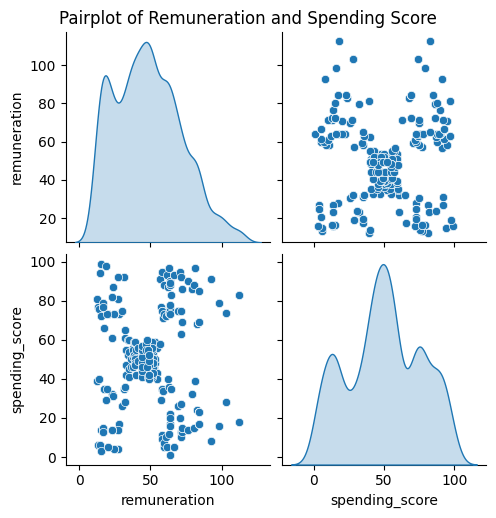

In [115]:
# Create a pairplot with Seaborn.
sns.pairplot(df3, diag_kind='kde')
plt.suptitle('Pairplot of Remuneration and Spending Score', y=1.02)
plt.show()

## 3. Elbow and silhoutte methods

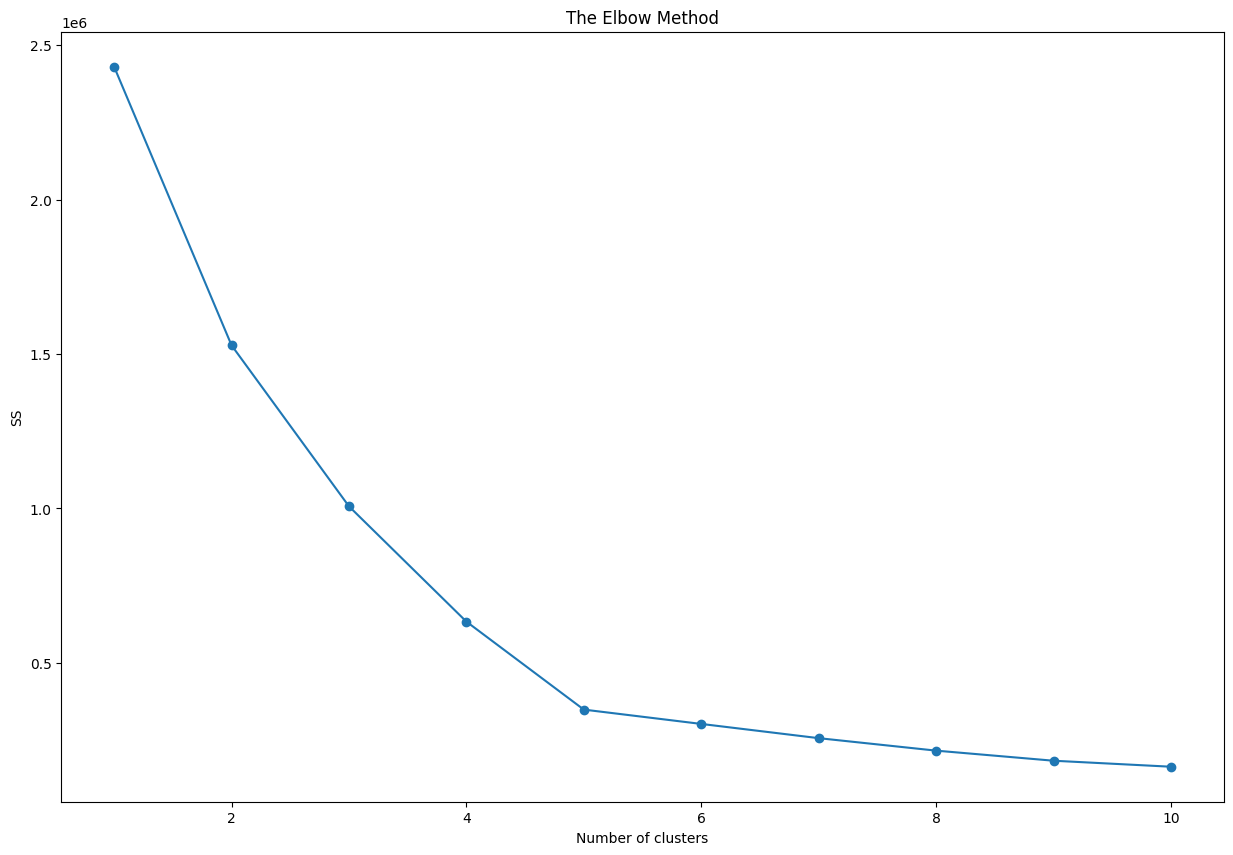

In [116]:
# Determine the number of clusters: Elbow method.
# Import the KMeans class.
from sklearn.cluster import KMeans 

# Elbow chart for us to decide on the number of optimal clusters.
ss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i,
                    init = 'k-means++', 
                    max_iter = 500,
                    n_init = 10,
                    random_state = 42)
    kmeans.fit(df3)
    ss.append(kmeans.inertia_)

plt.plot(range(1, 11),
         ss,
         marker='o')

plt.title("The Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("SS")

plt.show()

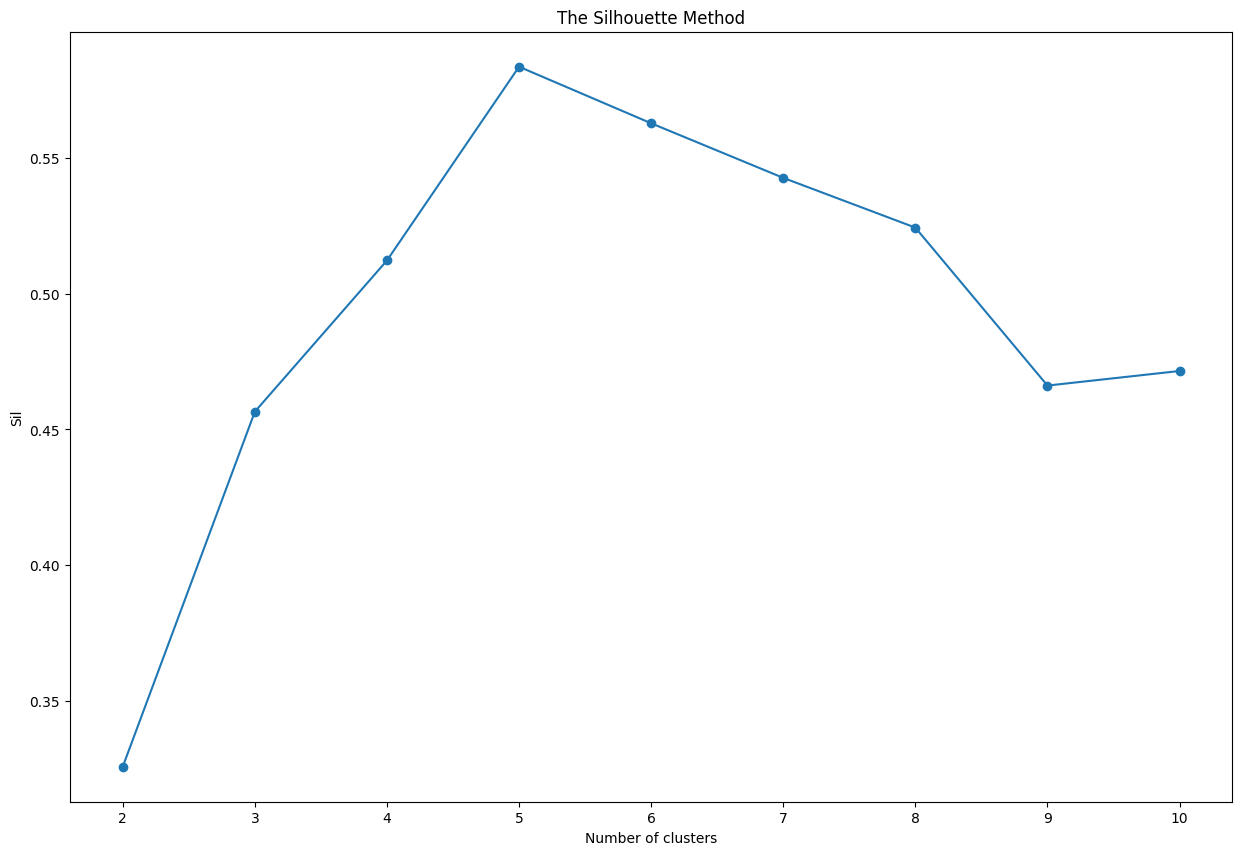

In [117]:
# Determine the number of clusters: Silhouette method.
# Import silhouette_score class from sklearn.
from sklearn.metrics import silhouette_score

# Find the range of clusters to be used using silhouette method.
sil = []
kmax = 10

for k in range(2, kmax+1):
    kmeans_s = KMeans(n_clusters = k).fit(df3)
    labels = kmeans_s.labels_
    sil.append(silhouette_score(df3,
                                labels,
                                metric = 'euclidean'))

# Plot the silhouette method.
plt.plot(range(2, kmax+1),
         sil,
         marker='o')

plt.title("The Silhouette Method")
plt.xlabel("Number of clusters")
plt.ylabel("Sil")

plt.show()

## 4. Evaluate k-means model at different values of *k*

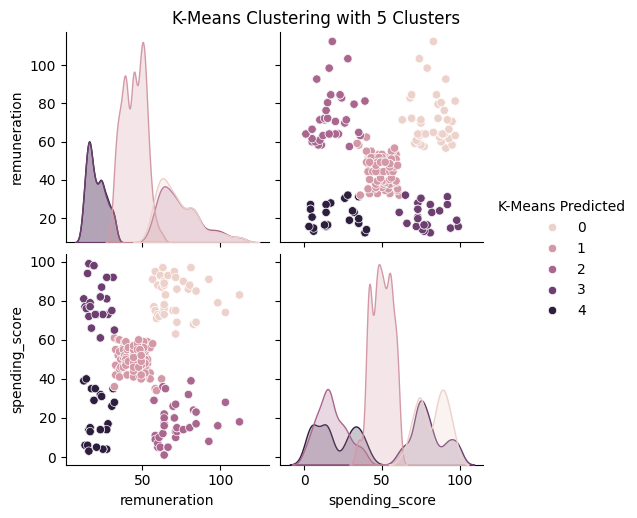

In [118]:
# We try to fit the model using k values of 5 and 6

# Use 5 clusters:
kmeans = KMeans(n_clusters = 5,
                max_iter = 15000,
                init='k-means++',
                random_state=42).fit(df3)

clusters = kmeans.labels_
df3['K-Means Predicted'] = clusters

# Plot the predicted.
sns.pairplot(df3,
             hue='K-Means Predicted',
             diag_kind= 'kde')

plt.suptitle('K-Means Clustering with 5 Clusters', y=1.02)
plt.show()

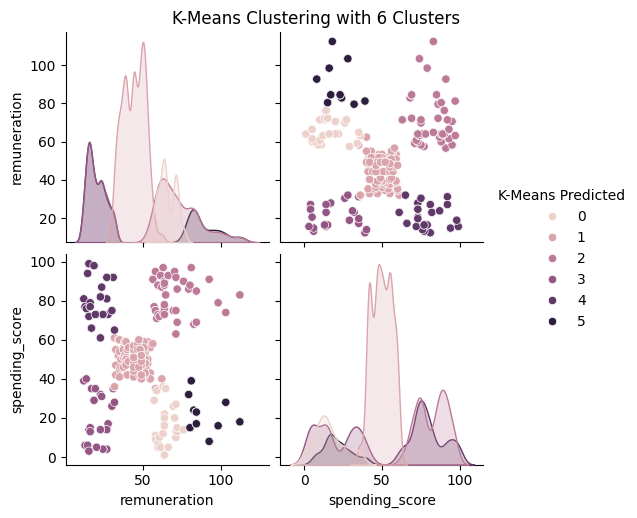

In [119]:
# Use 6 clusters:
kmeans = KMeans(n_clusters = 6,
                max_iter = 15000,
                init='k-means++',
                random_state=42).fit(df3)

clusters = kmeans.labels_
df3['K-Means Predicted'] = clusters

# Plot the predicted.
sns.pairplot(df3,
             hue='K-Means Predicted',
             diag_kind= 'kde')
plt.suptitle('K-Means Clustering with 6 Clusters', y=1.02)
plt.show()

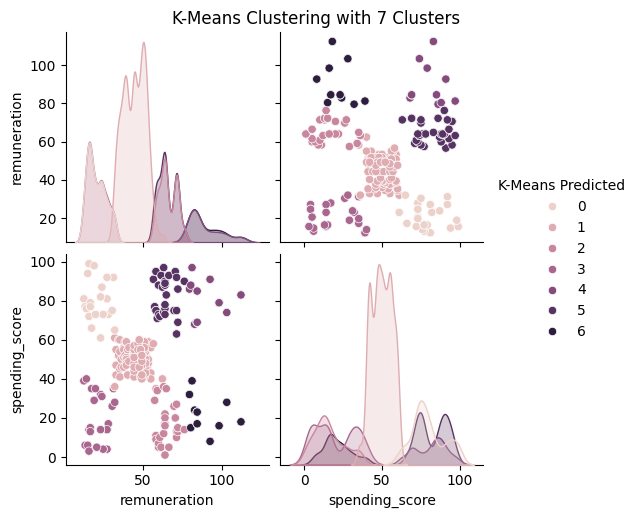

In [120]:
# Use 7 clusters:
kmeans = KMeans(n_clusters = 7,
                max_iter = 15000,
                init='k-means++',
                random_state=42).fit(df3)

clusters = kmeans.labels_
df3['K-Means Predicted'] = clusters

# Plot the predicted.
sns.pairplot(df3,
             hue='K-Means Predicted',
             diag_kind= 'kde')
plt.suptitle('K-Means Clustering with 7 Clusters', y=1.02)
plt.show()

## 5. Fit final model and justify your choice

In [121]:
# Apply the final model.
# Use 5 clusters:
kmeans = KMeans(n_clusters = 5,
                max_iter = 15000,
                init='k-means++',
                random_state=42).fit(df3)

clusters = kmeans.labels_
df3['K-Means Predicted'] = clusters


In [26]:
# Check the number of observations per predicted class.
df3['K-Means Predicted'].value_counts()

K-Means Predicted
1    774
0    356
2    330
4    271
3    269
Name: count, dtype: int64

## 6. Plot and interpret the clusters

,remuneration,spending_score,K-Means Predicted
0,12.30,39,4
1,12.30,81,3
2,13.12,6,4
3,13.12,77,3
4,13.94,40,4


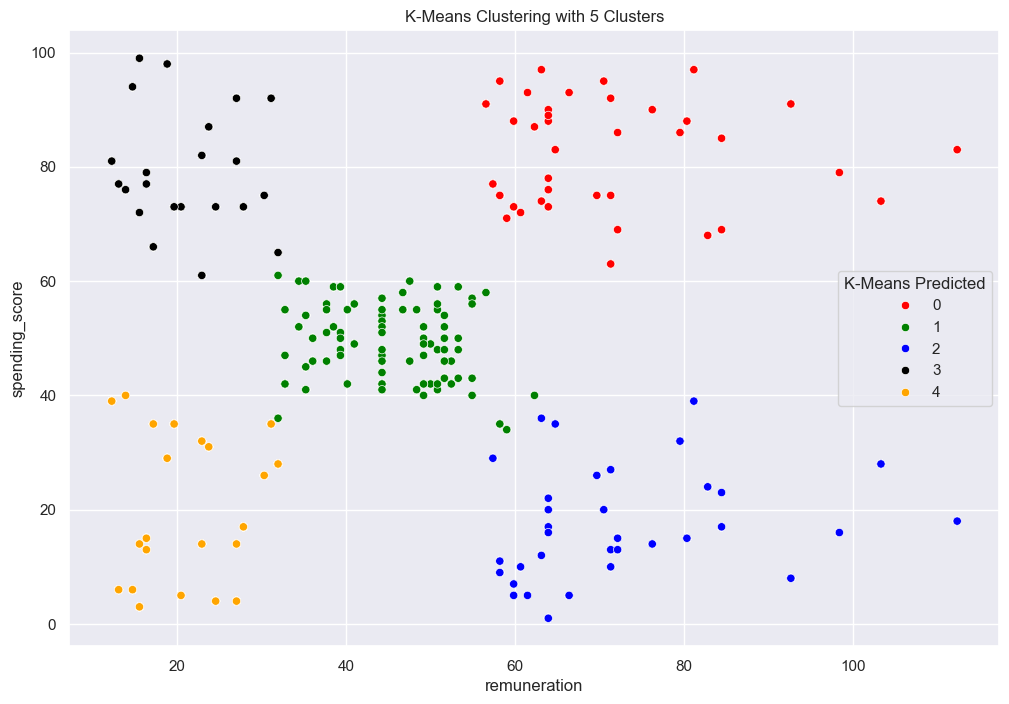

In [122]:
# Visualising the clusters.

# Set plot size.
sns.set(rc = {'figure.figsize':(12, 8)})

sns.scatterplot(x='remuneration', y='spending_score',
                data=df3 ,
                hue='K-Means Predicted',
                palette=['red', 'green', 'blue', 'black', 'orange'])
plt.title('K-Means Clustering with 5 Clusters')

# View the DataFrame.
df3.head()

## 7. Discuss: Insights and observations

***Your observations here...***

## Analysis

Both Elbow and Silhouette gives 5 cluster recommendation which is the ideal chooice considering how that reduces overall variance.

When we increase k beyond that what is really being observed is over segmentation and the algorithm failing to identify te noise due to small sample.

The kdes agree with this considering how we see distributions overlapping (their peaks almost coinciding) meaning kmeans have taken a band and split it into tiny sub clusters with similar distributions.--> we dont see new modes.--> multiple clusters in te same high density region..

On the other hand we can suggest also that we keep the no of clusters 5 while acknowledhng that the higher remuneration and lower spending group and higher spending and highe remuneration groups can have sub groups - mediumm high remun/high high rem low spending and mediumm high remun/high high rem high spending


# 

# Week 4 assignment: NLP using Python
Customer reviews were downloaded from the website of Turtle Games. This data will be used to steer the marketing department on how to approach future campaigns. Therefore, the marketing department asked you to identify the 15 most common words used in online product reviews. They also want to have a list of the top 20 positive and negative reviews received from the website. Therefore, you need to apply NLP on the data set.

## Instructions
1. Load and explore the data. 
    1. Sense-check the DataFrame.
    2. You only need to retain the `review` and `summary` columns.
    3. Determine if there are any missing values.
2. Prepare the data for NLP
    1. Change to lower case and join the elements in each of the columns respectively (`review` and `summary`).
    2. Replace punctuation in each of the columns respectively (`review` and `summary`).
    3. Drop duplicates in both columns (`review` and `summary`).
3. Tokenise and create wordclouds for the respective columns (separately).
    1. Create a copy of the DataFrame.
    2. Apply tokenisation on both columns.
    3. Create and plot a wordcloud image.
4. Frequency distribution and polarity.
    1. Create frequency distribution.
    2. Remove alphanumeric characters and stopwords.
    3. Create wordcloud without stopwords.
    4. Identify 15 most common words and polarity.
5. Review polarity and sentiment.
    1. Plot histograms of polarity (use 15 bins) for both columns.
    2. Review the sentiment scores for the respective columns.
6. Identify and print the top 20 positive and negative reviews and summaries respectively.
7. Include your insights and observations.

## 1. Load and explore the data

In [139]:
# Import all the necessary packages.
import pandas as pd
import numpy as np
import nltk 
import os 
import matplotlib.pyplot as plt

# nltk.download ('punkt').
# nltk.download ('stopwords').

from wordcloud import WordCloud
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from textblob import TextBlob
from scipy.stats import norm

# Import Counter.
from collections import Counter

import warnings
warnings.filterwarnings('ignore')

In [140]:
# Load the data set as df3.
df3 = pd.read_csv('turtle_reviews_cleaned.csv')
df3_original = df3.copy()
pd.set_option('display.max_colwidth', None)

# View DataFrame.
df3['review']


0                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

In [141]:
# Explore data set.
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gender          2000 non-null   object 
 1   age             2000 non-null   int64  
 2   remuneration    2000 non-null   float64
 3   spending_score  2000 non-null   int64  
 4   loyalty_points  2000 non-null   int64  
 5   education       2000 non-null   object 
 6   product         2000 non-null   int64  
 7   review          2000 non-null   object 
 8   summary         2000 non-null   object 
dtypes: float64(1), int64(4), object(4)
memory usage: 140.8+ KB


In [142]:
# Keep necessary columns. Drop unnecessary columns.
df3 = df3[['review', 'summary']]

# View DataFrame.
df3.head()


,review,summary
0,"When it comes to a DM's screen, the space on the screen itself is at an absolute premium. The fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless. The only reason that I gave it 2 stars and not 1 was that, technically speaking, it can at least still stand up to block your notes and dice rolls. Other than that, it drops the ball completely.",The fact that 50% of this space is wasted on art (and not terribly informative or needed art ...
1,"An Open Letter to GaleForce9*:\n\nYour unpainted miniatures are very not bad. Your spell cards are great. Your board games are ""meh"". Your DM screens, however, are freaking terrible. I'm still waiting for a single screen that isn't polluted with pointless artwork where useful, reference-able tables should be. Once again, you've created a single use screen that is only useful when running the ""Storm King's Thunder"" adventure. Even despite the fact that it's geared to that adventure path, it's usefulness negligible, at best. I massive swath of the inner panel is wasted on artwork and a bloated overland map, which could have been easily reduced to a single panel in size. And the few table you have are nigh-useless themselves.\n\nIn short, stop making crap DM screens.",Another worthless Dungeon Master's screen from GaleForce9
2,"Nice art, nice printing. Why two panels are filled with a general Forgotten Realms map is beyond me. Most of one of them is all blue ocean. Such a waste.\n\nI don't understand why they can't make these DM Screens more useful for these ""kinds of adventures"" rather than solely the specific adventure. You're supposed to be able to transpose this adventure to other lands outside the Forgotten Realms. So even just a list of new monsters or NPCs would at least be useful than the map. Even more would just be stuff related to running the game but broad-use stuff related to giants.\n\nSame thing with Curse of Strahd. Why not make it useful for raven loft, undead or horror campaigns in general... instead a huge amount of screen space is solely mapping out Castle Ravenloft, which is only useful during a small fraction of the time even for the Curse of Strahd adventure, let alone various other Ravenloft adventuring.\n\nThey really kill the extended use of these screens by not thinking about their potential use, both for the adventure in question, as well as use in a broader sense.\n\nThe Rage of Demons screen is far more useful for broad under dark adventuring - covering a lot of rules for the various conditions you may suffer... and the map is only one panel.\n\nThis Storm Giants one is decent for a few tables it includes - but really misses the mark. Maybe they should ask a few DMs what they would use?","pretty, but also pretty useless"
3,Amazing buy! Bought it as a gift for our new dm and it's perfect!,Five Stars
4,"As my review of GF9's previous screens these were completely unnecessary and nearly useless. Skip them, this is the definition of a waste of money.",Money trap


In [143]:
# Determine if there are any missing values.
df3.isnull().sum()

review     0
summary    0
dtype: int64

## 2. Prepare the data for NLP
### 2a) Change to lower case and join the elements in each of the columns respectively (review and summary)

In [144]:
# Review: Change all to lower case and join with a space.
df3['review'] = df3['review'].apply(lambda x: ' '.join(x.lower() for x in x.split()))


In [145]:
# Summary: Change all to lower case and join with a space.
df3['summary'] = df3['summary'].apply(lambda x: ' '.join(x.lower() for x in x.split()))

### 2b) Replace punctuation in each of the columns respectively (review and summary)

In [146]:
# Replace all the punctuations in review column.
df3['review'] = df3['review'].str.replace('[^\w\s]', '', regex=True)

# View output.
df3.head()


,review,summary
0,when it comes to a dms screen the space on the screen itself is at an absolute premium the fact that 50 of this space is wasted on art and not terribly informative or needed art as well makes it completely useless the only reason that i gave it 2 stars and not 1 was that technically speaking it can at least still stand up to block your notes and dice rolls other than that it drops the ball completely,the fact that 50% of this space is wasted on art (and not terribly informative or needed art ...
1,an open letter to galeforce9 your unpainted miniatures are very not bad your spell cards are great your board games are meh your dm screens however are freaking terrible im still waiting for a single screen that isnt polluted with pointless artwork where useful referenceable tables should be once again youve created a single use screen that is only useful when running the storm kings thunder adventure even despite the fact that its geared to that adventure path its usefulness negligible at best i massive swath of the inner panel is wasted on artwork and a bloated overland map which could have been easily reduced to a single panel in size and the few table you have are nighuseless themselves in short stop making crap dm screens,another worthless dungeon master's screen from galeforce9
2,nice art nice printing why two panels are filled with a general forgotten realms map is beyond me most of one of them is all blue ocean such a waste i dont understand why they cant make these dm screens more useful for these kinds of adventures rather than solely the specific adventure youre supposed to be able to transpose this adventure to other lands outside the forgotten realms so even just a list of new monsters or npcs would at least be useful than the map even more would just be stuff related to running the game but broaduse stuff related to giants same thing with curse of strahd why not make it useful for raven loft undead or horror campaigns in general instead a huge amount of screen space is solely mapping out castle ravenloft which is only useful during a small fraction of the time even for the curse of strahd adventure let alone various other ravenloft adventuring they really kill the extended use of these screens by not thinking about their potential use both for the adventure in question as well as use in a broader sense the rage of demons screen is far more useful for broad under dark adventuring covering a lot of rules for the various conditions you may suffer and the map is only one panel this storm giants one is decent for a few tables it includes but really misses the mark maybe they should ask a few dms what they would use,"pretty, but also pretty useless"
3,amazing buy bought it as a gift for our new dm and its perfect,five stars
4,as my review of gf9s previous screens these were completely unnecessary and nearly useless skip them this is the definition of a waste of money,money trap


In [147]:
# Replace all the punctuations in summary column.

df3['summary'] = df3['summary'].str.replace('[^\w\s]', '', regex=True)

# View output.

df3.head()


,review,summary
0,when it comes to a dms screen the space on the screen itself is at an absolute premium the fact that 50 of this space is wasted on art and not terribly informative or needed art as well makes it completely useless the only reason that i gave it 2 stars and not 1 was that technically speaking it can at least still stand up to block your notes and dice rolls other than that it drops the ball completely,the fact that 50 of this space is wasted on art and not terribly informative or needed art
1,an open letter to galeforce9 your unpainted miniatures are very not bad your spell cards are great your board games are meh your dm screens however are freaking terrible im still waiting for a single screen that isnt polluted with pointless artwork where useful referenceable tables should be once again youve created a single use screen that is only useful when running the storm kings thunder adventure even despite the fact that its geared to that adventure path its usefulness negligible at best i massive swath of the inner panel is wasted on artwork and a bloated overland map which could have been easily reduced to a single panel in size and the few table you have are nighuseless themselves in short stop making crap dm screens,another worthless dungeon masters screen from galeforce9
2,nice art nice printing why two panels are filled with a general forgotten realms map is beyond me most of one of them is all blue ocean such a waste i dont understand why they cant make these dm screens more useful for these kinds of adventures rather than solely the specific adventure youre supposed to be able to transpose this adventure to other lands outside the forgotten realms so even just a list of new monsters or npcs would at least be useful than the map even more would just be stuff related to running the game but broaduse stuff related to giants same thing with curse of strahd why not make it useful for raven loft undead or horror campaigns in general instead a huge amount of screen space is solely mapping out castle ravenloft which is only useful during a small fraction of the time even for the curse of strahd adventure let alone various other ravenloft adventuring they really kill the extended use of these screens by not thinking about their potential use both for the adventure in question as well as use in a broader sense the rage of demons screen is far more useful for broad under dark adventuring covering a lot of rules for the various conditions you may suffer and the map is only one panel this storm giants one is decent for a few tables it includes but really misses the mark maybe they should ask a few dms what they would use,pretty but also pretty useless
3,amazing buy bought it as a gift for our new dm and its perfect,five stars
4,as my review of gf9s previous screens these were completely unnecessary and nearly useless skip them this is the definition of a waste of money,money trap


### 2c) Drop duplicates in both columns

In [148]:
# Drop duplicates in both columns.
df3.drop_duplicates(subset=['review', 'summary'], inplace=True)
df3_original= df3_original[df3_original.index.isin(df3.index)]
# View DataFrame.
df3.head()

print(f'The shape of the DataFrame after removing duplicates is: {df3.shape}')
print(f'The shape of the original DataFrame after removing duplicates is: {df3_original.shape}')


The shape of the DataFrame after removing duplicates is: (1961, 2)
The shape of the original DataFrame after removing duplicates is: (1961, 9)


## 3. Tokenise and create wordclouds

In [149]:
# Create new DataFrame (copy DataFrame).
df3_copy = df3.copy()
    
# View DataFrame.
df3_copy.head()

,review,summary
0,when it comes to a dms screen the space on the screen itself is at an absolute premium the fact that 50 of this space is wasted on art and not terribly informative or needed art as well makes it completely useless the only reason that i gave it 2 stars and not 1 was that technically speaking it can at least still stand up to block your notes and dice rolls other than that it drops the ball completely,the fact that 50 of this space is wasted on art and not terribly informative or needed art
1,an open letter to galeforce9 your unpainted miniatures are very not bad your spell cards are great your board games are meh your dm screens however are freaking terrible im still waiting for a single screen that isnt polluted with pointless artwork where useful referenceable tables should be once again youve created a single use screen that is only useful when running the storm kings thunder adventure even despite the fact that its geared to that adventure path its usefulness negligible at best i massive swath of the inner panel is wasted on artwork and a bloated overland map which could have been easily reduced to a single panel in size and the few table you have are nighuseless themselves in short stop making crap dm screens,another worthless dungeon masters screen from galeforce9
2,nice art nice printing why two panels are filled with a general forgotten realms map is beyond me most of one of them is all blue ocean such a waste i dont understand why they cant make these dm screens more useful for these kinds of adventures rather than solely the specific adventure youre supposed to be able to transpose this adventure to other lands outside the forgotten realms so even just a list of new monsters or npcs would at least be useful than the map even more would just be stuff related to running the game but broaduse stuff related to giants same thing with curse of strahd why not make it useful for raven loft undead or horror campaigns in general instead a huge amount of screen space is solely mapping out castle ravenloft which is only useful during a small fraction of the time even for the curse of strahd adventure let alone various other ravenloft adventuring they really kill the extended use of these screens by not thinking about their potential use both for the adventure in question as well as use in a broader sense the rage of demons screen is far more useful for broad under dark adventuring covering a lot of rules for the various conditions you may suffer and the map is only one panel this storm giants one is decent for a few tables it includes but really misses the mark maybe they should ask a few dms what they would use,pretty but also pretty useless
3,amazing buy bought it as a gift for our new dm and its perfect,five stars
4,as my review of gf9s previous screens these were completely unnecessary and nearly useless skip them this is the definition of a waste of money,money trap


In [150]:
# Apply tokenisation to both columns.

df3['review_tokens'] = df3['review'].apply(word_tokenize)
df3['summary_tokens'] = df3['summary'].apply(word_tokenize)
# View DataFrame.
df3.head()

,review,summary,review_tokens,summary_tokens
0,when it comes to a dms screen the space on the screen itself is at an absolute premium the fact that 50 of this space is wasted on art and not terribly informative or needed art as well makes it completely useless the only reason that i gave it 2 stars and not 1 was that technically speaking it can at least still stand up to block your notes and dice rolls other than that it drops the ball completely,the fact that 50 of this space is wasted on art and not terribly informative or needed art,"[when, it, comes, to, a, dms, screen, the, space, on, the, screen, itself, is, at, an, absolute, premium, the, fact, that, 50, of, this, space, is, wasted, on, art, and, not, terribly, informative, or, needed, art, as, well, makes, it, completely, useless, the, only, reason, that, i, gave, it, 2, stars, and, not, 1, was, that, technically, speaking, it, can, at, least, still, stand, up, to, block, your, notes, and, dice, rolls, other, than, that, it, drops, the, ball, completely]","[the, fact, that, 50, of, this, space, is, wasted, on, art, and, not, terribly, informative, or, needed, art]"
1,an open letter to galeforce9 your unpainted miniatures are very not bad your spell cards are great your board games are meh your dm screens however are freaking terrible im still waiting for a single screen that isnt polluted with pointless artwork where useful referenceable tables should be once again youve created a single use screen that is only useful when running the storm kings thunder adventure even despite the fact that its geared to that adventure path its usefulness negligible at best i massive swath of the inner panel is wasted on artwork and a bloated overland map which could have been easily reduced to a single panel in size and the few table you have are nighuseless themselves in short stop making crap dm screens,another worthless dungeon masters screen from galeforce9,"[an, open, letter, to, galeforce9, your, unpainted, miniatures, are, very, not, bad, your, spell, cards, are, great, your, board, games, are, meh, your, dm, screens, however, are, freaking, terrible, im, still, waiting, for, a, single, screen, that, isnt, polluted, with, pointless, artwork, where, useful, referenceable, tables, should, be, once, again, youve, created, a, single, use, screen, that, is, only, useful, when, running, the, storm, kings, thunder, adventure, even, despite, the, fact, that, its, geared, to, that, adventure, path, its, usefulness, negligible, at, best, i, massive, swath, of, the, inner, panel, is, wasted, on, artwork, and, a, bloated, overland, map, which, ...]","[another, worthless, dungeon, masters, screen, from, galeforce9]"
2,nice art nice printing why two panels are filled with a general forgotten realms map is beyond me most of one of them is all blue ocean such a waste i dont understand why they cant make these dm screens more useful for these kinds of adventures rather than solely the specific adventure youre supposed to be able to transpose this adventure to other lands outside the forgotten realms so even just a list of new monsters or npcs would at least be useful than the map even more would just be stuff related to running the game but broaduse stuff related to giants same thing with curse of strahd why not make it useful for raven loft undead or horror campaigns in general instead a huge amount of screen space is solely mapping out castle ravenloft which is only useful during a small fraction of the time even for the curse of strahd adventure let alone various other ravenloft adventuring they really kill the extended use of these screens by not thinking about their potential use both for the adventure in question as well as use in a broader sense the rage of demons screen is far more useful for broad under dark adventuring covering a lot of rules for the various conditions you may suffer and the map is only one panel this storm giants one is decent for a few tables it includes but really 

In [151]:
# Review: Create a word cloud.

all_tokens_review = df3['review_tokens'].sum()
token_review_sentence = ' '.join(all_tokens_review)
wordcloud_review = WordCloud(width=800, height=500,
                             background_color='white',stopwords=set(),
                             colormap='viridis',
                             random_state=42).generate(token_review_sentence)
# View the word cloud.
wordcloud_review

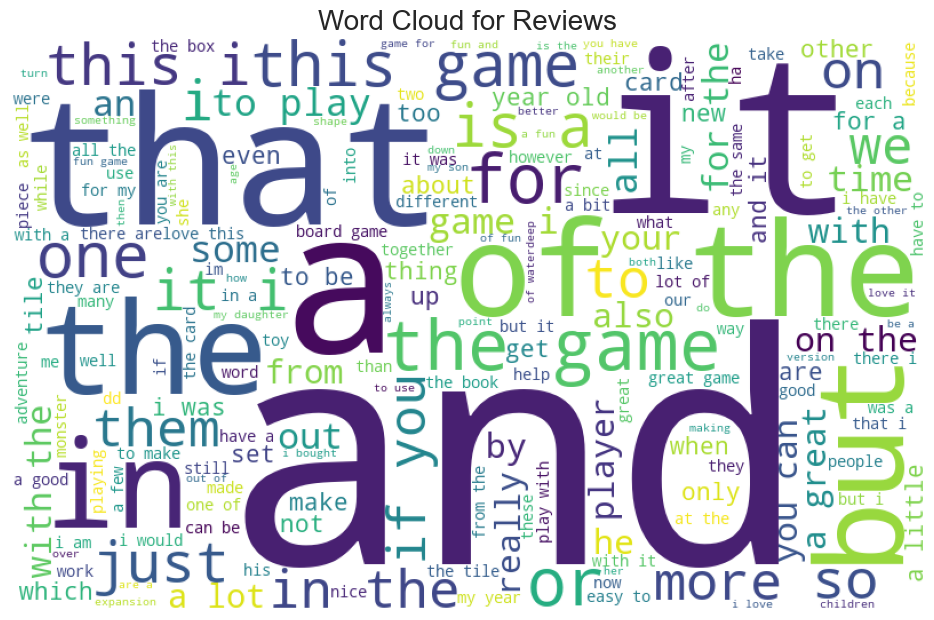

In [152]:
# Review: Plot the WordCloud image.
plt.figure(figsize=(10, 6))
plt.title('Word Cloud for Reviews', fontsize=20)
plt.imshow(wordcloud_review)
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

In [153]:
# Summary: Create a word cloud.

all_tokens_summary = df3['summary_tokens'].sum()
token_summary_sentence = ' '.join(all_tokens_summary)
wordcloud_summary = WordCloud(width=800, height=500,
                             background_color='white',
                             colormap='viridis',
                             random_state=42).generate(token_summary_sentence)
# View the word cloud.
wordcloud_summary

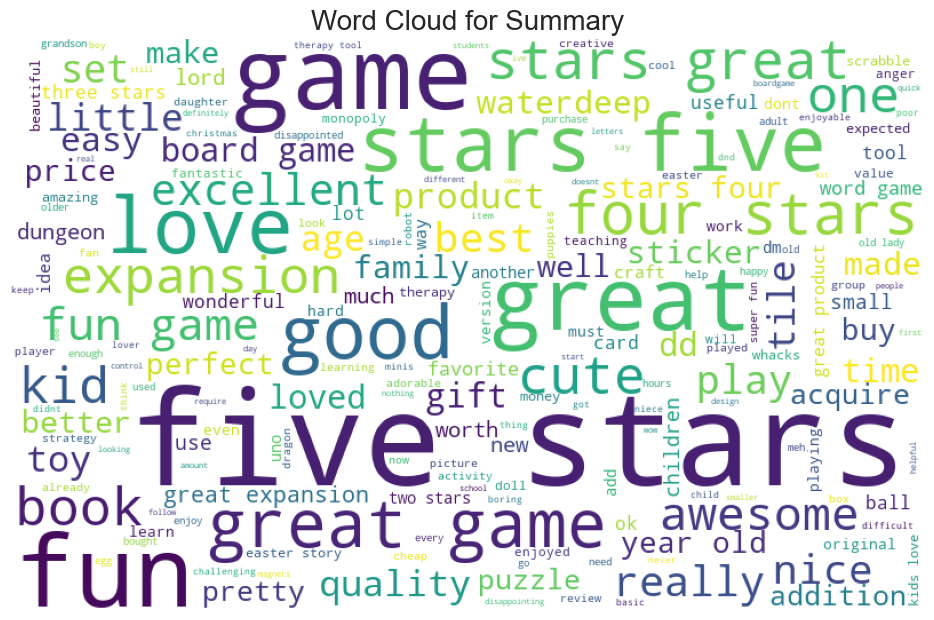

In [154]:
# Summary: Plot the WordCloud image.
plt.figure(figsize=(10, 6))
plt.title('Word Cloud for Summary', fontsize=20)
plt.imshow(wordcloud_summary)
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

## 4. Frequency distribution and polarity
### 4.1 Create frequency distribution

In [155]:
# Determine the frequency distribution.
fqdist_review = FreqDist(all_tokens_review)
# View the frequency distribution.
fqdist_review


FreqDist({'the': 5451, 'and': 3233, 'to': 3162, 'a': 3160, 'of': 2488, 'i': 2090, 'it': 2083, 'is': 1782, 'this': 1776, 'game': 1671, ...})

### 4.2 Remove alphanumeric characters and stopwords

In [156]:
# Delete all the alphanum.
all_tokens_review = [word for word in all_tokens_review if  word.isalnum()]

In [157]:
# Remove all the stopwords
all_tokens_review = [word for word in all_tokens_review if word not in stopwords.words('english')]

### 4.3 Create wordcloud without stopwords

In [158]:
# Create a wordcloud without stop words.
wordcloud_review = WordCloud(width=800, height=500,
                             background_color='white',
                             colormap='viridis',
                             random_state=42).generate(' '.join(all_tokens_review))
# View the word cloud.
wordcloud_review

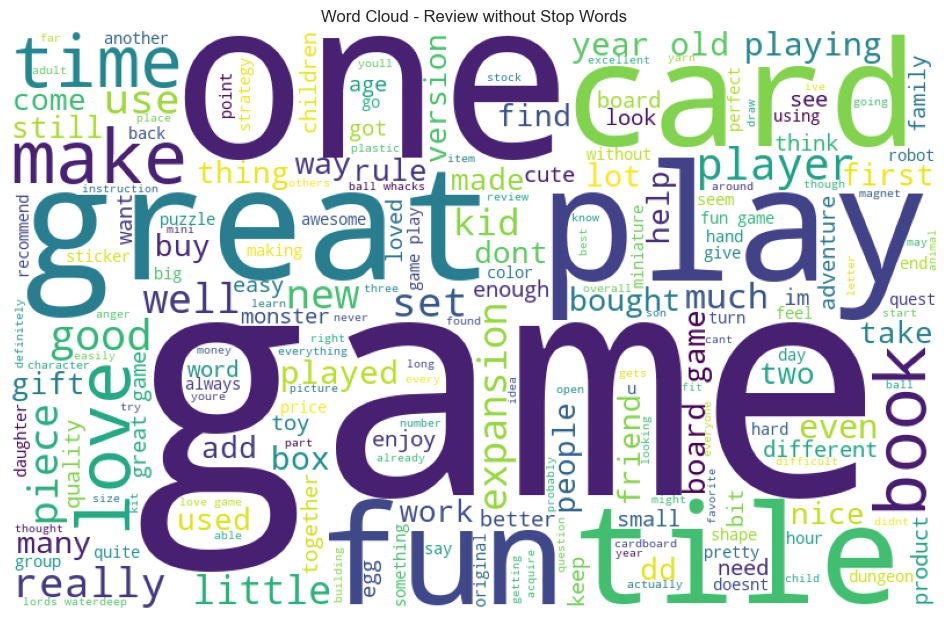

In [159]:
# Plot the wordcloud image.

plt.figure(figsize=(10, 6))
plt.title('Word Cloud - Review without Stop Words')
plt.imshow(wordcloud_review)
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

### 4.4 Identify 15 most common words and polarity

In [160]:
# Determine the 15 most common words.
fqdist_review = FreqDist(all_tokens_review)
fqdist_review.most_common(15)

[('game', 1671),
 ('great', 580),
 ('fun', 552),
 ('one', 530),
 ('play', 502),
 ('like', 414),
 ('love', 323),
 ('really', 319),
 ('get', 319),
 ('cards', 301),
 ('tiles', 297),
 ('time', 291),
 ('good', 289),
 ('would', 280),
 ('book', 273)]

## 5. Review polarity and sentiment: Plot histograms of polarity (use 15 bins) and sentiment scores for the respective columns.

### 5.1 Finding polarity of reviews & sentences

In [161]:
# Provided function.
def generate_polarity(comment):
    '''Extract polarity score (-1 to +1) for each comment'''
    return TextBlob(comment).sentiment[0]

In [162]:
# Determine polarity of both columns. 
df3['review_polarity'] = df3['review'].apply(generate_polarity)
df3['summary_polarity'] = df3['summary'].apply(generate_polarity)

# View output.
df3.head()

,review,summary,review_tokens,summary_tokens,review_polarity,summary_polarity
0,when it comes to a dms screen the space on the screen itself is at an absolute premium the fact that 50 of this space is wasted on art and not terribly informative or needed art as well makes it completely useless the only reason that i gave it 2 stars and not 1 was that technically speaking it can at least still stand up to block your notes and dice rolls other than that it drops the ball completely,the fact that 50 of this space is wasted on art and not terribly informative or needed art,"[when, it, comes, to, a, dms, screen, the, space, on, the, screen, itself, is, at, an, absolute, premium, the, fact, that, 50, of, this, space, is, wasted, on, art, and, not, terribly, informative, or, needed, art, as, well, makes, it, completely, useless, the, only, reason, that, i, gave, it, 2, stars, and, not, 1, was, that, technically, speaking, it, can, at, least, still, stand, up, to, block, your, notes, and, dice, rolls, other, than, that, it, drops, the, ball, completely]","[the, fact, that, 50, of, this, space, is, wasted, on, art, and, not, terribly, informative, or, needed, art]",-0.036111,0.15
1,an open letter to galeforce9 your unpainted miniatures are very not bad your spell cards are great your board games are meh your dm screens however are freaking terrible im still waiting for a single screen that isnt polluted with pointless artwork where useful referenceable tables should be once again youve created a single use screen that is only useful when running the storm kings thunder adventure even despite the fact that its geared to that adventure path its usefulness negligible at best i massive swath of the inner panel is wasted on artwork and a bloated overland map which could have been easily reduced to a single panel in size and the few table you have are nighuseless themselves in short stop making crap dm screens,another worthless dungeon masters screen from galeforce9,"[an, open, letter, to, galeforce9, your, unpainted, miniatures, are, very, not, bad, your, spell, cards, are, great, your, board, games, are, meh, your, dm, screens, however, are, freaking, terrible, im, still, waiting, for, a, single, screen, that, isnt, polluted, with, pointless, artwork, where, useful, referenceable, tables, should, be, once, again, youve, created, a, single, use, screen, that, is, only, useful, when, running, the, storm, kings, thunder, adventure, even, despite, the, fact, that, its, geared, to, that, adventure, path, its, usefulness, negligible, at, best, i, massive, swath, of, the, inner, panel, is, wasted, on, artwork, and, a, bloated, overland, map, which, ...]","[another, worthless, dungeon, masters, screen, from, galeforce9]",0.035952,-0.80
2,nice art nice printing why two panels are filled with a general forgotten realms map is beyond me most of one of them is all blue ocean such a waste i dont understand why they cant make these dm screens more useful for these kinds of adventures rather than solely the specific adventure youre supposed to be able to transpose this adventure to other lands outside the forgotten realms so even just a list of new monsters or npcs would at least be useful than the map even more would just be stuff related to running the game but broaduse stuff related to giants same thing with curse of strahd why not make it useful for raven loft undead or horror campaigns in general instead a huge amount of screen space is solely mapping out castle ravenloft which is only useful during a small fraction of the time even for the curse of strahd adventure let alone various other ravenloft adventuring they really kill the extended use of these screens by not thinking about their potential use both for the adventure in question as well as use in a broader sense the rage of demons screen is far more useful for broad under dark adventuring covering a lot of rules for the various conditions you may suffer and the map is only one panel this stor

### 5.2 Histogram Plots of summaries & reviews

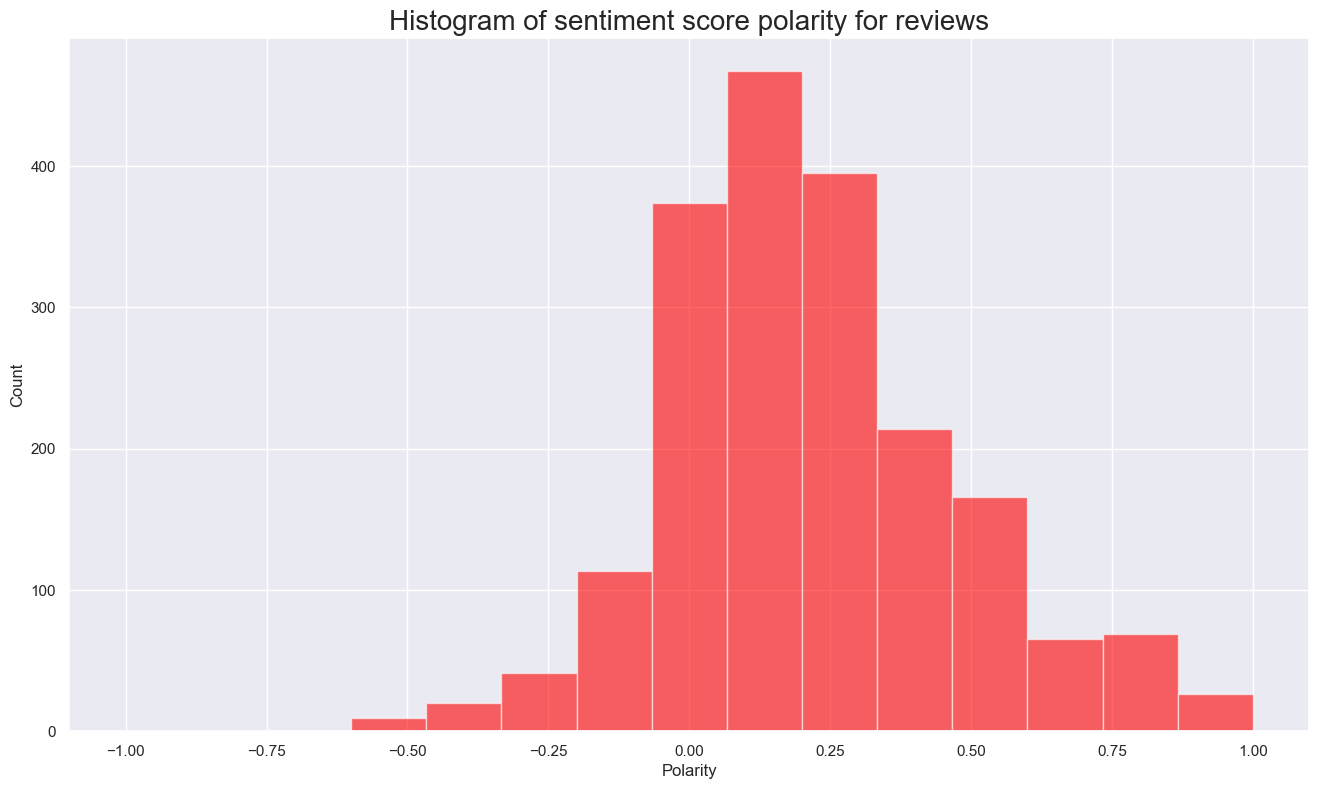

In [163]:
# Review: Create a histogram plot with bins = 15.
# Histogram of polarity
# no of bins
num_bins = 15
plt.figure(figsize = (16,9))

n, bins, patches = plt.hist(df3['review_polarity'],  num_bins, facecolor ='red', alpha = 0.6)

# Set the labels.

plt.xlabel('Polarity', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.title('Histogram of sentiment score polarity for reviews', fontsize=20)

plt.show()





### 5.3 Histogram Plots of summaries & reviews

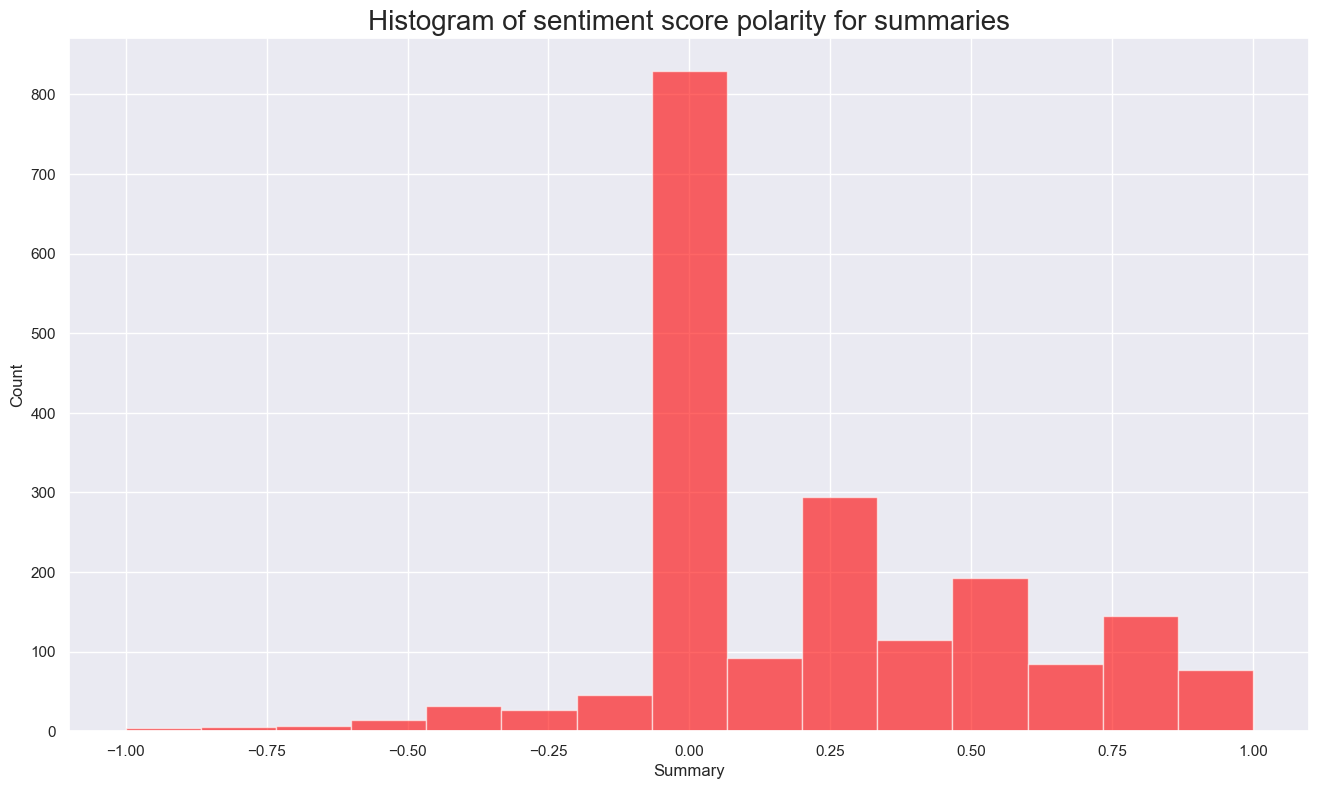

In [164]:
# Summary: Create a histogram plot with bins = 15.
# Histogram of polarity
num_bins = 15
plt.figure(figsize = (16,9))

n, bins, patches = plt.hist(df3['summary_polarity'],  num_bins, facecolor ='red', alpha = 0.6)

# Set the labels.
plt.xlabel('Summary', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.title('Histogram of sentiment score polarity for summaries', fontsize=20)

plt.show()




### 5.3 % split up of summaries & reviews sentimnent

In [196]:
# 1) Convert polarity to simple labels 
def polarity_label(p, pos_thr=0.05, neg_thr=-0.05):
    if p > pos_thr:
        return "Positive"
    elif p < neg_thr:
        return "Negative"
    else:
        return "Neutral"

df3["review_sentiment"] = df3["review_polarity"].apply(polarity_label)
df3["summary_sentiment"] = df3["summary_polarity"].apply(polarity_label)

# 2) Compact sentiment distribution tables (%)
review_dist = df3["review_sentiment"].value_counts(normalize=True).mul(100).round(1)
summary_dist = df3["summary_sentiment"].value_counts(normalize=True).mul(100).round(1)

print("Review sentiment %:\n", review_dist)
print("\nSummary sentiment %:\n", summary_dist)

# Optional: mean/median polarity (report-friendly)
print("\nReview polarity mean/median:", df3["review_polarity"].mean().round(3), df3["review_polarity"].median().round(3))
print("Summary polarity mean/median:", df3["summary_polarity"].mean().round(3), df3["summary_polarity"].median().round(3))


Review sentiment %:
 review_sentiment
Positive    73.9
Neutral     14.6
Negative    11.4
Name: proportion, dtype: float64

Summary sentiment %:
 summary_sentiment
Positive    51.6
Neutral     39.9
Negative     8.6
Name: proportion, dtype: float64

Review polarity mean/median: 0.213 0.177
Summary polarity mean/median: 0.224 0.1


## 6. Identify top 20 positive and negative reviews and summaries respectively

### 6.1 Top 20 Negative Reviews

In [197]:
# Top 20 negative reviews.

# Get the indices of the 20 rows with smallest review polarity from df3
idx = df3.nsmallest(20, 'review_polarity').index

# Select those rows from df3 (which contains 'review_polarity') and keep the two columns
df3['original_review'] = df3_original['review']
df3['remuneration'] = df3_original['remuneration']
df3['age'] = df3_original['age']
negative_reviews = df3.loc[idx, ['original_review', 'review_polarity', 'remuneration', 'age']].copy()
def remuneration_category(value):
    if 13.12<=value < 22.96:
        return 'Low'
    elif 22.96 <= value < 61.295:
        return 'Medium'
    else:
        return 'High'

def age_category(value):
    if 18 <= value < 32:
        return 'Young Adult'
    elif 32 <= value < 50:
        return 'Middle Aged'
    else:
        return 'Senior'
    
def spending_category(value):
    if 0<=value < 40:
        return 'Low'
    elif 40 <= value < 60:
        return 'Medium'
    else:
        return 'High'
negative_reviews['remuneration_category'] = negative_reviews['remuneration'].apply(remuneration_category)
negative_reviews['age_category'] = negative_reviews['age'].apply(age_category)
negative_reviews['rem_age_category'] = negative_reviews['remuneration_category'] + ' - ' + negative_reviews['age_category']
print(negative_reviews['rem_age_category'].mode())

# View output.
negative_reviews.style.set_properties(subset=['original_review'], **{'width': '1200px'})


0    Medium - Middle Aged
Name: rem_age_category, dtype: object


,original_review,review_polarity,remuneration,age,remuneration_category,age_category,rem_age_category
208,BOOO UNLES YOU ARE PATIENT KNOW HOW TO MEASURE I DIDN'T HAVE THE PATIENCE NEITHER DID MY DAUGHTER. BORING UNLESS YOU ARE A CRAFT PERSON WHICH I AM NOT.,-1.000000,15.580000,66,Low,Senior,Low - Senior
182,Incomplete kit! Very disappointing!,-0.780000,80.360000,44,High,Middle Aged,High - Middle Aged
1804,"I'm sorry. I just find this product to be boring and, to be frank, juvenile.",-0.583333,13.120000,33,Low,Middle Aged,Low - Middle Aged
364,"One of my staff will be using this game soon, so I don't know how well it works as yet, but after looking at the cards, I believe it will be helpful in getting a conversation started regarding anger and what to do to control it.",-0.550000,69.700000,49,High,Middle Aged,High - Middle Aged
117,I bought this as a Christmas gift for my grandson. Its a sticker book. So how can I go wrong with this gift.,-0.500000,53.300000,49,Medium,Middle Aged,Medium - Middle Aged
227,this was a gift for my daughter. I found it difficult to use,-0.500000,22.960000,37,Medium,Middle Aged,Medium - Middle Aged
230,I found the directions difficult,-0.500000,24.600000,62,Medium,Senior,Medium - Senior
290,Instructions are complicated to follow,-0.500000,48.380000,70,Medium,Senior,Medium - Senior
301,Difficult,-0.500000,50.840000,49,Medium,Middle Aged,Medium - Middle Aged
1524,Expensive for what you get.,-0.500000,72.160000,25,High,Young Adult,High - Young Adult


### 6.2 Wordcloud - Top 20 Negative Reviews (Lemmatized)

In [198]:
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.corpus import stopwords
from wordcloud import WordCloud
import nltk
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")


# Lemmatizing preparation
lemm = WordNetLemmatizer()
stop = set(stopwords.words("english")) 

def get_wordnet_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("N"): return wordnet.NOUN
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

# Tokenizing the reviews.
negative_reviews = negative_reviews['original_review'].apply(word_tokenize)
negative_reviews = [w for toks in negative_reviews.tolist() for w in toks]
# Delete all the alphanumeric tokens.
negative_reviews= [word for word in negative_reviews if  word.isalnum()]

# lowercase BEFORE stopword removal 
negative_reviews = [w.lower() for w in negative_reviews]

# Remove all the stopwords
negative_reviews = [word for word in negative_reviews if word not in stopwords.words('english')]

# lemmatise (collapses disappointed/disappointing -> disappoint)
tagged = pos_tag(negative_reviews)
negative_reviews = [lemm.lemmatize(w, get_wordnet_pos(t)) for w, t in tagged]
# Top 20 negative reviews words
negative_reviews_freq = FreqDist(negative_reviews)
print(negative_reviews_freq.most_common(20))
negative_reviews  = ' '.join(negative_reviews)
wordcloud_review = WordCloud(collocations=True, collocation_threshold=10,width=800, height=500,
                             background_color='white',stopwords=set(),
                             colormap='viridis',
                             random_state=42).generate(negative_reviews)
# View the word cloud.
wordcloud_review

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/jayaramgokulan/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/jayaramgokulan/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/jayaramgokulan/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/jayaramgokulan/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


[('game', 7), ('gift', 5), ('find', 4), ('work', 4), ('child', 4), ('difficult', 3), ('make', 3), ('son', 3), ('love', 3), ('know', 2), ('daughter', 2), ('boring', 2), ('craft', 2), ('kit', 2), ('product', 2), ('use', 2), ('get', 2), ('buy', 2), ('direction', 2), ('complicate', 2)]


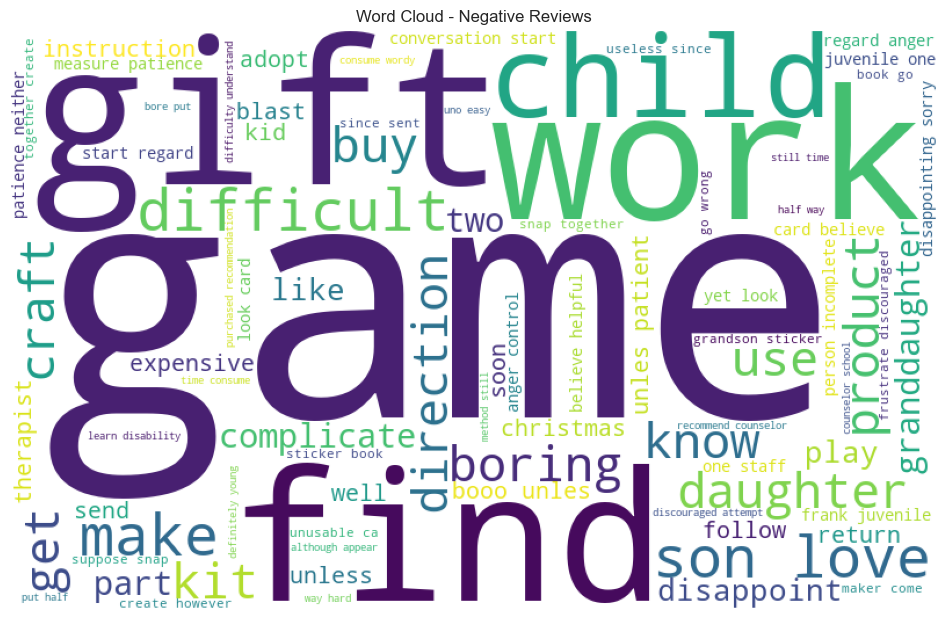

In [168]:
# Plot the wordcloud image.

plt.figure(figsize=(10, 6))
plt.title('Word Cloud - Negative Reviews')
plt.imshow(wordcloud_review)
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

### 6.3 Top 20 Negative Summaries

In [199]:
# Top 20 negative summaries.

# Get the indices of the 20 rows with smallest summary polarity from df3
idx = df3.nsmallest(20, 'summary_polarity').index

# Select those rows from df3 (which contains 'summary_polarity') and keep the two columns
df3['original_summary'] = df3_original['summary']
negative_summaries = df3.loc[idx, ['original_summary', 'summary_polarity']]

# View output.
pd.set_option('display.max_colwidth', None)

negative_summaries.style.set_properties(
    subset=['original_summary'],
    **{'width': '800px', 'white-space': 'normal'}
)

,original_summary,summary_polarity
21,The worst value I've ever seen,-1.000000
208,BORING UNLESS YOU ARE A CRAFT PERSON WHICH I AM ...,-1.000000
829,Boring,-1.000000
1166,before this I hated running any RPG campaign dealing with towns because it ...,-0.900000
1,Another worthless Dungeon Master's screen from GaleForce9,-0.800000
144,Disappointed,-0.750000
631,Disappointed.,-0.750000
793,Disappointed,-0.750000
1620,Disappointed,-0.750000
363,Promotes anger instead of teaching calming methods,-0.700000


### 6.4 Wordcloud - Top 20 Negative Summaries (Lemmatized)

In [200]:
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.corpus import stopwords
from wordcloud import WordCloud
import nltk
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")


lemm = WordNetLemmatizer()
stop = set(stopwords.words("english"))  # define once (faster + cleaner)

def get_wordnet_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("N"): return wordnet.NOUN
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

negative_summaries = negative_summaries['original_summary'].apply(word_tokenize)
negative_summaries = [w for toks in negative_summaries.tolist() for w in toks]
# Delete all the alphanum.
negative_summaries= [word for word in negative_summaries if  word.isalnum()]

# 4) lowercase BEFORE stopword removal (important)
negative_summaries = [w.lower() for w in negative_summaries]

# Remove all the stopwords
negative_summaries = [word for word in negative_summaries if word not in stopwords.words('english')]

# 6) lemmatise (collapses disappointed/disappointing -> disappoint)
tagged = pos_tag(negative_summaries)
negative_summaries = [lemm.lemmatize(w, get_wordnet_pos(t)) for w, t in tagged]
# Top 20 positive summaries words
negative_summary_freq = FreqDist(negative_summaries)
print(negative_summary_freq.most_common(20))
negative_summaries  = ' '.join(negative_summaries)
wordcloud_review = WordCloud(collocations=True, collocation_threshold=10,width=800, height=500,
                             background_color='white',stopwords=set(),
                             colormap='viridis',
                             random_state=42).generate(negative_summaries)
# View the word cloud.
wordcloud_review

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/jayaramgokulan/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/jayaramgokulan/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/jayaramgokulan/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/jayaramgokulan/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


[('bad', 3), ('bore', 3), ('disappointed', 3), ('disappointing', 3), ('disappoint', 2), ('make', 2), ('find', 2), ('value', 1), ('ever', 1), ('see', 1), ('unless', 1), ('craft', 1), ('person', 1), ('hat', 1), ('run', 1), ('rpg', 1), ('campaign', 1), ('deal', 1), ('town', 1), ('another', 1)]


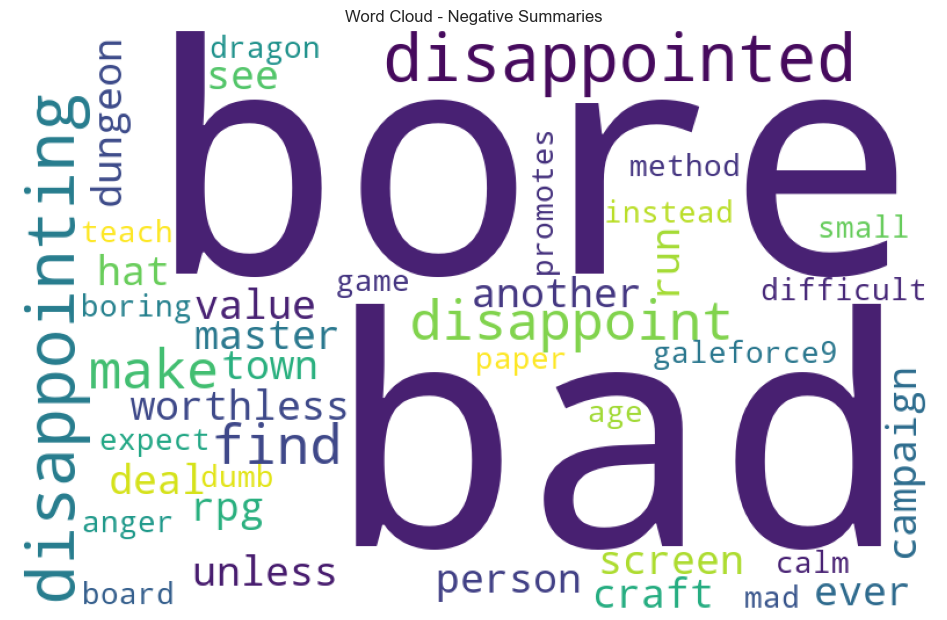

In [171]:
# Plot the wordcloud image.

plt.figure(figsize=(10, 6))

plt.title('Word Cloud - Negative Summaries')
plt.imshow(wordcloud_review)
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

### 6.5 Top 20 Positive Reviews

In [189]:
# Top 20 positive reviews.

idx = df3.nlargest(20, 'review_polarity').index

df3['original_review'] = df3_original['review']
positive_reviews = df3.loc[idx, ['original_review', 'review_polarity']]
# View output.
positive_reviews.style.set_properties(subset=['original_review'], **{'width': '1200px'})

,original_review,review_polarity
7,Came in perfect condition.,1.000000
165,Awesome book,1.000000
194,Awesome gift,1.000000
496,Excellent activity for teaching self-management skills!,1.000000
524,"Perfect, just what I ordered!!",1.000000
591,Wonderful product,1.000000
609,Delightful product!,1.000000
621,Wonderful for my grandson to learn the resurrection story.,1.000000
790,Perfect!,1.000000
933,Awesome,1.000000


### 6.6 Wordcloud - Top 20 Positive Reviews (Lemmatized)

In [190]:

# Lemmatizing preparation
lemm = WordNetLemmatizer()
stop = set(stopwords.words("english"))  # define once (faster + cleaner)

# Function to map POS tag to first character lemmatize() accepts
def get_wordnet_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("N"): return wordnet.NOUN
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

positive_reviews = positive_reviews['original_review'].apply(word_tokenize)
positive_reviews = [w for toks in positive_reviews.tolist() for w in toks]
# Delete all the nonalphanumeric
positive_reviews= [word for word in positive_reviews if  word.isalnum()]

# lowercase BEFORE stopword removal (important)
positive_reviews = [w.lower() for w in positive_reviews]

# Remove all the stopwords
positive_reviews = [word for word in positive_reviews if word not in stopwords.words('english')]

# lemmatise (collapses disappointed/disappointing -> disappoint)
tagged = pos_tag(positive_reviews)
positive_reviews = [lemm.lemmatize(w, get_wordnet_pos(t)) for w, t in tagged]
# Top 20 positive summaries words
positive_reviews_freq = FreqDist(positive_reviews)
print(positive_reviews_freq.most_common(20))
positive_reviews  = ' '.join(positive_reviews)
wordcloud_review = WordCloud(collocations=True, collocation_threshold=10,width=800, height=500,
                             background_color='white',stopwords=set(),
                             colormap='viridis',
                             random_state=42).generate(positive_reviews)
# View the word cloud.
wordcloud_review

[('awesome', 8), ('perfect', 4), ('best', 3), ('excellent', 2), ('order', 2), ('wonderful', 2), ('product', 2), ('set', 2), ('play', 2), ('toy', 2), ('come', 1), ('condition', 1), ('book', 1), ('gift', 1), ('activity', 1), ('teach', 1), ('skill', 1), ('delightful', 1), ('grandson', 1), ('learn', 1)]


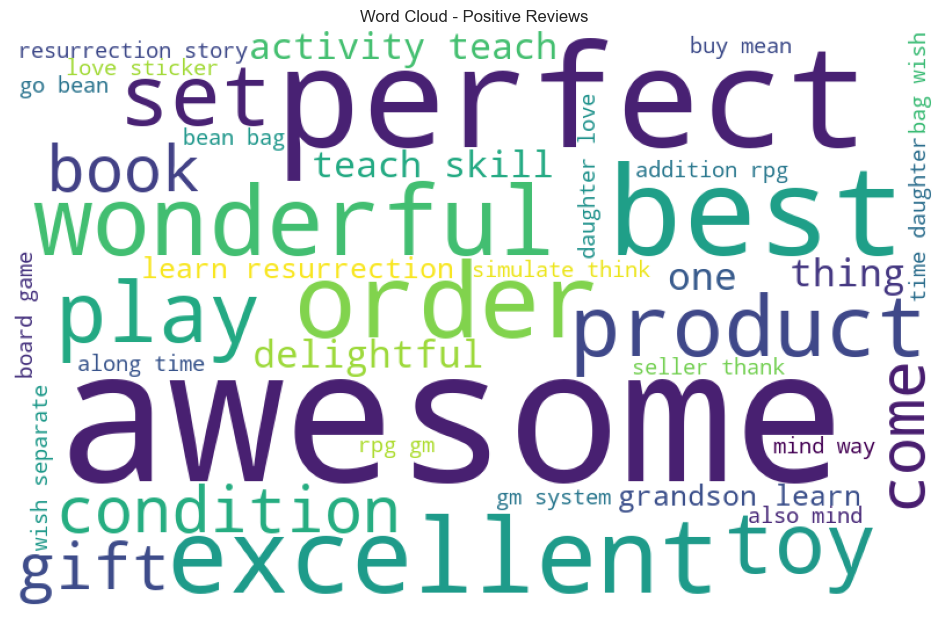

In [184]:
# Plot the wordcloud image.

plt.figure(figsize=(10, 6))

plt.title('Word Cloud - Positive Reviews')
plt.imshow(wordcloud_review)
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

### 6.6 Top 20 Positive Summaries

In [187]:
# Top 20 positive summaries.

idx = df3.nlargest(20, 'summary_polarity').index
df3['original_summary'] = df3_original['summary']
positive_summaries = df3.loc[idx, ['original_summary', 'summary_polarity']]
# View output.
positive_summaries.style.set_properties(subset=['original_summary'], **{'width': '1200px'})

,original_summary,summary_polarity
6,Best gm screen ever,1.000000
28,Wonderful designs.,1.000000
32,Perfect!,1.000000
80,They're the perfect size to keep in the car or a diaper ...,1.000000
134,Perfect for Preschooler,1.000000
140,Awesome sticker activity for the price,1.000000
161,Awesome Book...,1.000000
163,He was very happy with his gift,1.000000
187,Awesome,1.000000
210,Awesome and well-designed for 9 year olds,1.000000


### 6.7 Wordcloud - Top 20 Positive Summaries (Lemmatized)

In [188]:
lemm = WordNetLemmatizer()
stop = set(stopwords.words("english"))  # define once (faster + cleaner)

def get_wordnet_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("N"): return wordnet.NOUN
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

positive_summaries = positive_summaries['original_summary'].apply(word_tokenize)
positive_summaries = [w for toks in positive_summaries.tolist() for w in toks]
# Delete all the alphanum.
positive_summaries= [word for word in positive_summaries if  word.isalnum()]

# 4) lowercase BEFORE stopword removal (important)
positive_summaries = [w.lower() for w in positive_summaries]

# Remove all the stopwords
positive_summaries = [word for word in positive_summaries if word not in stopwords.words('english')]

# 6) lemmatise (collapses disappointed/disappointing -> disappoint)
tagged = pos_tag(positive_summaries)
positive_summaries = [lemm.lemmatize(w, get_wordnet_pos(t)) for w, t in tagged]
# Top 20 positive summaries words
positive_summary_freq = FreqDist(positive_summaries)
print(positive_summary_freq.most_common(20))
positive_summaries  = ' '.join(positive_summaries)
wordcloud_summary = WordCloud(collocations=True, collocation_threshold=10,width=800, height=500,
                             background_color='white',stopwords=set(),
                             colormap='viridis',
                             random_state=42).generate(positive_summaries)


# View the word cloud.
wordcloud_summary

[('perfect', 5), ('awesome', 5), ('best', 3), ('wonderful', 3), ('excellent', 3), ('tool', 2), ('gm', 1), ('screen', 1), ('ever', 1), ('design', 1), ('size', 1), ('keep', 1), ('car', 1), ('diaper', 1), ('preschooler', 1), ('sticker', 1), ('activity', 1), ('price', 1), ('book', 1), ('happy', 1)]


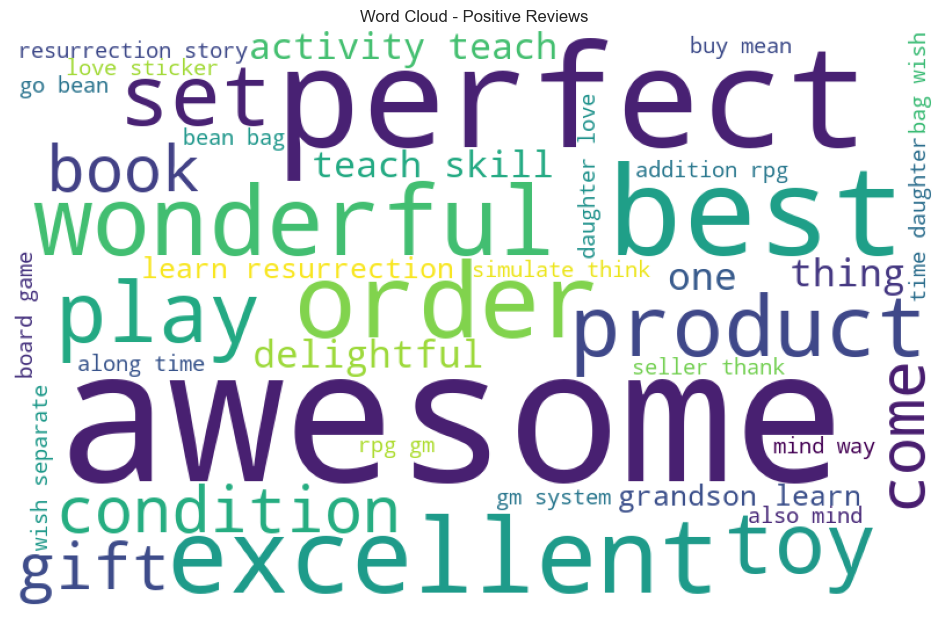

In [ ]:
# Plot the wordcloud image.

plt.figure(figsize=(10, 6))
plt.title('Word Cloud - Positive Reviews')
plt.imshow(wordcloud_review)
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

## 7. Sentiment Distribution & Statistics by Segments/Segment Combination (Remuneration/Age/Spend)

### 7.1 Creating Segment buckets & sentiment distribution

In [ ]:
# Attach structured fields back to df3 for segmentation analysis
df3["remuneration"] = df3_original["remuneration"]
df3["age"] = df3_original["age"]

# Recreating the segment buckets for ALL reviews 
df3["remuneration_category"] = df3["remuneration"].apply(remuneration_category)
df3["age_category"] = df3["age"].apply(age_category)
df3["rem_age_category"] = df3["remuneration_category"] + " - " + df3["age_category"]
df3["spending_category"] = df3_original["spending_score"].apply(spending_category)
df3["rem_spend_category"] = df3["remuneration_category"] + " - " + df3["spending_category"]
df3["age_spend_category"] = df3["age_category"] + " - " + df3["spending_category"]

#  Attach product back  ----
product_col = "product"  
df3[product_col] = df3_original[product_col]

bucket_cols = ["rem_age_category", "rem_spend_category", "age_spend_category"]

# Sentiment mix (%) for each bucket ----
seg_mix_all = pd.concat(
    [
        (df3.groupby(bucket)["review_sentiment"]
            .value_counts(normalize=True)
            .mul(100)
            .rename("pct")
            .reset_index()
            .assign(bucket_type=bucket)
            .rename(columns={bucket: "segment"})
        )
        for bucket in bucket_cols
    ],
    ignore_index=True
).sort_values(["bucket_type", "segment", "pct"], ascending=[True, True, False])

seg_mix_all.head(30)

,segment,review_sentiment,pct,bucket_type
53,Middle Aged - High,Positive,75.961538,age_spend_category
54,Middle Aged - High,Neutral,13.701923,age_spend_category
55,Middle Aged - High,Negative,10.336538,age_spend_category
56,Middle Aged - Low,Positive,76.011561,age_spend_category
57,Middle Aged - Low,Neutral,12.716763,age_spend_category
58,Middle Aged - Low,Negative,11.271676,age_spend_category
59,Middle Aged - Medium,Positive,71.052632,age_spend_category
60,Middle Aged - Medium,Neutral,17.434211,age_spend_category
61,Middle Aged - Medium,Negative,11.513158,age_spend_category
62,Senior - High,Positive,75.510204,age_spend_category


### 7.2 Sentiment Statistics across segment buckets

In [ ]:
# Mean polarity stats for each bucket 
seg_mean_all = pd.concat(
    [
        (df3.groupby(bucket)["review_polarity"]
            .agg(count="count", mean="mean", median="median")
            .reset_index()
            .assign(bucket_type=bucket)
            .rename(columns={bucket: "segment"})
        )
        for bucket in bucket_cols
    ],
    ignore_index=True
).sort_values(["bucket_type", "mean"], ascending=[True, True])

seg_mean_all.head(30)

,segment,count,mean,median,bucket_type
22,Senior - Low,147,0.183058,0.167177,age_spend_category
23,Senior - Medium,227,0.189669,0.168750,age_spend_category
26,Young Adult - Medium,183,0.197473,0.164807,age_spend_category
25,Young Adult - Low,105,0.200171,0.133462,age_spend_category
20,Middle Aged - Medium,304,0.209916,0.154841,age_spend_category
21,Senior - High,49,0.215198,0.175000,age_spend_category
18,Middle Aged - High,416,0.226600,0.200000,age_spend_category
24,Young Adult - High,184,0.227827,0.179101,age_spend_category
19,Middle Aged - Low,346,0.232261,0.199122,age_spend_category
4,Low - Senior,53,0.173764,0.165385,rem_age_category


### 7.3 Product lists across segment buckets

In [ ]:
# Product list per segment (top 5) ----
TOP_N = 5

segment_products = pd.concat(
    [
        (df3.groupby([bucket, product_col]).size()
            .rename("n")
            .reset_index()
            .assign(bucket_type=bucket)
            .rename(columns={bucket: "segment"})
        )
        for bucket in bucket_cols
    ],
    ignore_index=True
)

# Keep top N products within each (bucket_type, segment)
segment_products_top = (
    segment_products.sort_values(["bucket_type", "segment", "n"], ascending=[True, True, False])
                    .groupby(["bucket_type", "segment"])
                    .head(TOP_N)
)

# Making the product a list tyep
product_list_table = (
    segment_products_top.assign(prod_with_n=lambda d: d[product_col].astype(str) + " (" + d["n"].astype(int).astype(str) + ")")
                        .groupby(["bucket_type", "segment"])["prod_with_n"]
                        .apply(lambda s: ", ".join(s))
                        .rename("top_products")
                        .reset_index()
)

product_list_table.head(30)

,bucket_type,segment,top_products
0,age_spend_category,Middle Aged - High,"6504 (6), 7101 (6), 9080 (6), 263 (5), 760 (5)"
1,age_spend_category,Middle Aged - Low,"1012 (6), 4390 (6), 6507 (6), 107 (5), 3112 (5)"
2,age_spend_category,Middle Aged - Medium,"3525 (7), 1577 (5), 3427 (5), 3629 (5), 3885 (5)"
3,age_spend_category,Senior - High,"1940 (2), 3667 (2), 3878 (2), 3887 (2), 5429 (2)"
4,age_spend_category,Senior - Low,"618 (3), 1497 (3), 2173 (3), 2807 (3), 2870 (3)"
5,age_spend_category,Senior - Medium,"283 (6), 326 (5), 504 (5), 2521 (5), 9612 (5)"
6,age_spend_category,Young Adult - High,"107 (4), 624 (4), 977 (4), 2162 (4), 486 (3)"
7,age_spend_category,Young Adult - Low,"2495 (3), 2811 (3), 4491 (3), 4712 (3), 6471 (3)"
8,age_spend_category,Young Adult - Medium,"6233 (5), 999 (4), 2296 (4), 2371 (4), 3498 (4)"
9,rem_age_category,High - Middle Aged,"3112 (8), 4390 (8), 4415 (8), 6507 (8), 8962 (8)"


## 7.4 Discuss: Insights and observations

Observations:
1. The top 15 words for reviews & summaries are -
   
   Positive Summaries: [('perfect', 5), ('awesome', 5), ('best', 3), ('wonderful', 3), ('excellent', 3), ('tool', 2), ('gm', 1), ('screen', 1), ('ever', 1), ('design', 1), ('size', 1), ('keep', 1), ('car', 1), ('diaper', 1), ('preschooler', 1), ('sticker', 1), ('activity', 1), ('price', 1), ('book', 1), ('happy', 1)]
   
   Negative Reviews: [('game', 7), ('gift', 5), ('find', 4), ('work', 4), ('child', 4), ('difficult', 3), ('make', 3), ('son', 3), ('love', 3), ('know', 2), ('daughter', 2), ('boring', 2), ('craft', 2), ('kit', 2), ('product', 2), ('use', 2), ('get', 2), ('buy', 2), ('direction', 2), ('complicate', 2)]
   
   Positive Reviews: [('awesome', 8), ('perfect', 4), ('best', 3), ('excellent', 2), ('order', 2), ('wonderful', 2), ('product', 2), ('set', 2), ('play', 2), ('toy', 2), ('come', 1), ('condition', 1), ('book', 1), ('gift', 1), ('activity', 1), ('teach', 1), ('skill', 1), ('delightful', 1), ('grandson', 1), ('learn', 1)]
   
   Negative Summaries: [('bad', 3), ('bore', 3), ('disappointed', 3), ('disappointing', 3), ('disappoint', 2), ('make', 2), ('find', 2), ('value', 1), ('ever', 1), ('see', 1), ('unless', 1), ('craft', 1), ('person', 1), ('hat', 1), ('run', 1), ('rpg', 1), ('campaign', 1), ('deal', 1), ('town', 1), ('another', 1)]

Insights:
1. There are two practical ways to start tackling the problem using the review + summary text we analysed:

   a. **From the product perspective**  
   We can use the sentiment scores *along with the actual review text* to identify which products (and which product features) are causing the most worry to customers. The pain points are usually explicit in the wording (e.g., “difficult”, “poor quality”, “waste of money”).  
   This helps the marketing team understand what is failing in the customer experience, and then relay it to the relevant teams (e.g., R&D / product / ops) for quality improvement, redesign, packaging changes, or clearer instructions—whatever is required to make the product more suitable for customers.

   b. **From the customer perspective**  
   We can group the negative (and positive) reviews with customer attributes such as **age / remuneration / spending score** to see *which types of customers* are making specific complaints (or giving strong praise).  
   This supports targeted marketing: campaigns can be tuned to the right customer segments, and messaging/offers can be aligned with what each group values or struggles with. This also gives the product teams a clearer direction for improvements that benefit the specific groups identified.

2. **Segmentation via buckets adds structure to text insights.**  
   Instead of only reading reviews one-by-one, we can bucket customers into meaningful categories (e.g., remuneration bands + age bands, or age + spending), and then compare sentiment patterns across these segments. This makes the findings easier to action for both marketing and product teams.

3. **NLP preprocessing makes the text usable for analytics.**  
   The NLP steps we applied (lowercasing, punctuation removal, tokenisation, stopword removal, deduplication) help tidy up the text so it can be analysed systematically (word clouds, frequent terms, sentiment scoring, comparisons by group).

4. **Sentiment quality is mostly reasonable, but TextBlob has limitations.**  
   Comparing the polarity scores to the actual text, the sentiment looks correctly matched for most reviews and summaries, with a small number of mismatches. This highlights a limitation of TextBlob: it can struggle with negations, sarcasm, and sentence structures it has not seen before (e.g., *“Not the best quality”*).  
   This can be improved by using a stronger sentiment model (e.g., VADER or transformer-based sentiment) if higher accuracy is required.

5. **Summary text quality may weaken sentiment signals.**  
   On inspection, many entries in the `summary` column contain ellipsis / incomplete text. Since TextBlob is sensitive to sentence completeness and context, this could reduce the quality of the summary sentiment compared to the full review text.


# 